In [211]:
import torch
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # Set to -1 to disable all GPUs

# Force PyTorch to use CPU
device = torch.device('cpu')

In [212]:
import pickle


In [213]:
import cv2
from PIL import Image
from torchvision import transforms
import json
import pycocotools.mask as mask
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from copy import deepcopy
import torch
import math
#import io
#import base64  # Import the base64 module
def get_video_frames(video_path):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        print("Error: Cannot open video file.")
        return
        #exit()

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = int(cap.get(cv2.CAP_PROP_FPS))

    frame_list = []
    # Loop through the frames and convert them to PIL images
    for frame_number in range(frame_count):
        ret, frame = cap.read()

        if not ret:
            print(f"Error reading frame {frame_number + 1}")
            continue

        # Convert the OpenCV frame to a PIL Image
        frame_pil = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

        # Append the PIL image to the list
        frame_list.append(frame_pil)

    cap.release()
    return frame_list

def calculate_iou(box1, box2):
    x1_min, y1_min, x1_max, y1_max = box1
    x2_min, y2_min, x2_max, y2_max = box2

    # Calculate areas
    area1 = (x1_max - x1_min) * (y1_max - y1_min)
    area2 = (x2_max - x2_min) * (y2_max - y2_min)

    # Calculate intersection coordinates
    x_intersection_min = max(x1_min, x2_min)
    y_intersection_min = max(y1_min, y2_min)
    x_intersection_max = min(x1_max, x2_max)
    y_intersection_max = min(y1_max, y2_max)

    # Check for no overlap
    if x_intersection_max <= x_intersection_min or y_intersection_max <= y_intersection_min:
        return 0.0

    # Calculate area of intersection
    intersection_area = (x_intersection_max - x_intersection_min) * (y_intersection_max - y_intersection_min)

    # Calculate IoU
    iou = intersection_area / (area1 + area2 - intersection_area)

    return iou


In [214]:
def get_list_with_removed_elements(data_list,
                                  indices_to_remove_list
                                 ):
        return [element for index, element in enumerate(data_list) if index not in indices_to_remove_list]
    
def filter_data_and_recompute_max_objs(or_obj_proposals_struct,
                                       or_person_proposals_struct, 
                                       min_rel_score_thresh, 
                                       min_obj_score_thresh):
        num_att_rels_removed_total = 0
        num_spatial_rels_removed_total = 0
        num_contact_rels_removed_total = 0
        num_objs_removed_total = 0

        num_orig_total_objs = 0
        num_orig_att_rels = 0
        num_orig_spatial_rels = 0
        num_orig_contact_rels = 0
        max_num_objs_for_frame = 0
        or_obj_proposals_struct = deepcopy(or_obj_proposals_struct)
        or_person_proposals_struct = deepcopy(or_person_proposals_struct)
        for video_id, video_struct in or_obj_proposals_struct.items():
            #print('hello')
            for frame_id, obj_struct_list in video_struct['frames'].items():
                obj_indices_to_remove = []
                new_obj_struct_list = []
                #print(len(obj_struct_list))
                #input()
                for obj_i, obj_struct in enumerate(obj_struct_list):
                    num_orig_total_objs+=1
                    if('obj_score' in obj_struct and obj_struct['obj_score'][0]<min_obj_score_thresh):
                        obj_indices_to_remove.append(obj_i)
                        num_objs_removed_total+=1

                    if('attention_relationship_scores' in obj_struct):
                        rel_indices_to_remove = []
                        for rel_i, rel_score in enumerate(obj_struct['attention_relationship_scores']):
                            num_orig_att_rels+=1
                            if(rel_score<min_rel_score_thresh):
                                rel_indices_to_remove.append(rel_i)
                                num_att_rels_removed_total+=1
                        obj_struct['attention_relationship_scores'] = get_list_with_removed_elements(obj_struct['attention_relationship_scores'], rel_indices_to_remove)
                        obj_struct['attention_relationship'] = get_list_with_removed_elements(obj_struct['attention_relationship'], rel_indices_to_remove)


                    if('spatial_relationship_scores' in obj_struct):
                        rel_indices_to_remove = []
                        for rel_i, rel_score in enumerate(obj_struct['spatial_relationship_scores']):
                            num_orig_spatial_rels+=1
                            if(rel_score<min_rel_score_thresh):
                                rel_indices_to_remove.append(rel_i)
                                num_spatial_rels_removed_total+=1
                        obj_struct['spatial_relationship_scores'] = get_list_with_removed_elements(obj_struct['spatial_relationship_scores'], rel_indices_to_remove)
                        obj_struct['spatial_relationship'] = get_list_with_removed_elements(obj_struct['spatial_relationship'], rel_indices_to_remove)

                    if('contacting_relationship_scores' in obj_struct):
                        rel_indices_to_remove = []
                        for rel_i, rel_score in enumerate(obj_struct['contacting_relationship_scores']):
                            num_orig_contact_rels+=1
                            if(rel_score<min_rel_score_thresh):
                                rel_indices_to_remove.append(rel_i)
                                num_contact_rels_removed_total+=1
                        #for rel_i_r in rel_indices_to_remove:
                        obj_struct['contacting_relationship_scores'] = get_list_with_removed_elements(obj_struct['contacting_relationship_scores'], rel_indices_to_remove)
                        obj_struct['contacting_relationship'] = get_list_with_removed_elements(obj_struct['contacting_relationship'], rel_indices_to_remove)
                    new_obj_struct_list.append(obj_struct)
                    
                #print(obj_indices_to_remove)
                #print(len(obj_struct_list))
                filt_obj_struct_list = get_list_with_removed_elements(new_obj_struct_list, obj_indices_to_remove)
                or_obj_proposals_struct[video_id]['frames'][frame_id] = filt_obj_struct_list
                max_num_objs_for_frame = max(len(filt_obj_struct_list), max_num_objs_for_frame)
                #for obj_i_r in obj_indices_to_remove:
                 #   obj_struct_list.pop(obj_i_r)

        print(f"Filtered {num_att_rels_removed_total} number of att relations from original {num_orig_att_rels} ({100*num_att_rels_removed_total/num_orig_att_rels:.2f}%)")
        print(f"Filtered {num_spatial_rels_removed_total} number of spatial relations from original {num_orig_spatial_rels} ({100*num_spatial_rels_removed_total/num_orig_spatial_rels:.2f}%)")
        print(f"Filtered {num_contact_rels_removed_total} number of contact relations from original {num_orig_contact_rels} ({100*num_contact_rels_removed_total/num_orig_contact_rels:.2f}%)")
        print(f"Filtered {num_objs_removed_total} number of objects from original {num_orig_total_objs} ({100*num_objs_removed_total/num_orig_total_objs:.2f}%)")
        return or_obj_proposals_struct, or_person_proposals_struct, max_num_objs_for_frame


In [215]:
obj_bboxes_pred['001YG.mp4']['frames']['000543.png']

[{'class': 'bag',
  'obj_score': array([0.82218677], dtype=float32),
  'bbox': (147.49237, 149.52257, 95.359085, 112.103806),
  'attention_relationship': ['looking_at', 'not_looking_at'],
  'attention_relationship_scores': [2.56892466545105, 0.9707286357879639],
  'spatial_relationship': ['in_front_of'],
  'spatial_relationship_scores': [1.0],
  'contacting_relationship': ['holding', 'touching'],
  'contacting_relationship_scores': [1.0, 1.0],
  'metadata': None,
  'visible': True},
 {'class': 'chair',
  'obj_score': array([0.99979764], dtype=float32),
  'bbox': (26.274591, 215.48007, 49.383003, 55.67697),
  'attention_relationship': ['not_looking_at'],
  'attention_relationship_scores': [6.761409282684326],
  'spatial_relationship': ['beneath', 'behind'],
  'spatial_relationship_scores': [1.0, 1.0],
  'contacting_relationship': ['leaning_on', 'sitting_on'],
  'contacting_relationship_scores': [1.0, 1.0],
  'metadata': None,
  'visible': True},
 {'class': 'food',
  'obj_score': array([

In [147]:
out1, out2, num = filter_data_and_recompute_max_objs(obj_bboxes_pred, 
                                                     person_bboxes_pred,
                                                     0.9,
                                                     0.85
                                                    )

Filtered 191913 number of att relations from original 1310724 (14.64%)
Filtered 107827 number of spatial relations from original 1751942 (6.15%)
Filtered 188689 number of contact relations from original 2057686 (9.17%)
Filtered 520686 number of objects from original 1107951 (47.00%)


In [152]:
out1['001YG.mp4']['frames']['000543.png']

[{'class': 'chair',
  'obj_score': array([0.99979764], dtype=float32),
  'bbox': (26.274591, 215.48007, 49.383003, 55.67697),
  'attention_relationship': ['not_looking_at'],
  'attention_relationship_scores': [6.761409282684326],
  'spatial_relationship': ['beneath', 'behind'],
  'spatial_relationship_scores': [1.0, 1.0],
  'contacting_relationship': ['leaning_on', 'sitting_on'],
  'contacting_relationship_scores': [1.0, 1.0],
  'metadata': None,
  'visible': True},
 {'class': 'laptop',
  'obj_score': array([0.99385023], dtype=float32),
  'bbox': (344.654, 134.67741, 126.7836, 97.427536),
  'attention_relationship': ['looking_at'],
  'attention_relationship_scores': [1.128836989402771],
  'spatial_relationship': ['in_front_of'],
  'spatial_relationship_scores': [0.9999998807907104],
  'contacting_relationship': ['not_contacting'],
  'contacting_relationship_scores': [1.0],
  'metadata': None,
  'visible': True},
 {'class': 'table',
  'obj_score': array([0.98323166], dtype=float32),
  '

In [158]:
set([1,2,3]) - set([1,2])

{3}

In [161]:
person_bboxes_gt['8Z02S.mp4']['frames']['000579.png']

{'bbox': array([[  0.      ,   3.234842, 246.71237 , 269.6625  ]], dtype=float32),
 'bbox_score': array([0.920466], dtype=float32),
 'bbox_size': (480, 270),
 'bbox_mode': 'xyxy',
 'keypoints': array([[[245.86862  ,  25.99923  ,   1.       ],
         [245.86862  ,  17.905226 ,   1.       ],
         [236.75613  ,  18.242476 ,   1.       ],
         [ 23.118738 ,  78.94751  ,   1.       ],
         [ 23.793737 ,  73.88876  ,   1.       ],
         [109.856186 ,  21.277727 ,   1.       ],
         [ 42.356228 ,   4.0779676,   1.       ],
         [215.83113  ,  37.128487 ,   1.       ],
         [ 93.9937   , 140.32706  ,   1.       ],
         [184.10614  ,  78.27301  ,   1.       ],
         [194.90614  ,  65.120255 ,   1.       ],
         [ 84.20621  , 252.96861  ,   1.       ],
         [ 62.26872  , 241.5021   ,   1.       ],
         [216.16862  ,  42.86174  ,   1.       ],
         [215.83113  ,  42.86174  ,   1.       ],
         [184.44365  ,  77.93576  ,   1.       ],
       

In [198]:
import pickle
obj_bboxes_gt = pickle.load(open("/data/usrdata/shan/STAR_VideoQA/obj_bboxes_by_videoid.pkl",'rb'))
person_bboxes_gt = pickle.load(open("/data/usrdata/shan/STAR_VideoQA/person_bboxes_by_videoid.pkl",'rb'))
obj_bboxes_pred = pickle.load(open("/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_obj_bboxes_objthresh0.3_relthresh0.5.pkl",'rb'))
person_bboxes_pred = pickle.load(open('/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_person_bboxes.pkl','rb'))

In [199]:
'000579.png' in obj_bboxes_pred['8Z02S.mp4']['frames'].keys()

True

In [207]:
cases_where_person_frameid_missing = []
cases_where_obj_frameid_missing = []

for vid_id, struct in obj_bboxes_pred.items():
    if(set(struct['frames'].keys()) != set(person_bboxes_pred[vid_id]['frames'].keys())):
        print('hello')
        missing_keys_for_person_bbox = set(struct['frames'].keys()) - set(person_bboxes_pred[vid_id]['frames'].keys()) 
        for missing_key in missing_keys_for_person_bbox:
            cases_where_person_frameid_missing.append((vid_id, missing_key))#, type(missing_key))
            person_bboxes_pred[vid_id]['frames'][missing_key] = person_bboxes_gt[vid_id]['frames'][missing_key]
            
        missing_keys_for_obj_bbox = set(person_bboxes_pred[vid_id]['frames'].keys())  - set(struct['frames'].keys())
        for missing_key in missing_keys_for_obj_bbox:
            cases_where_obj_frameid_missing.append((vid_id, missing_key))#, type(missing_key))
            obj_bboxes_pred[vid_id]['frames'][missing_key] = obj_bboxes_gt[vid_id]['frames'][missing_key]
            
        #cases.append((vid_id, set(struct['frames'].keys()) - set(person_bboxes_pred[vid_id]['frames'].keys()), set(person_bboxes_pred[vid_id]['frames'].keys()) - set(struct['frames'].keys())))
    #if('frames' in obj_bboxes_pred[vid_id]['vid_info']): 
     #   print('hello')
      #  obj_bboxes_pred[vid_id]['vid_info'] = obj_bboxes_pred[vid_id]['vid_info']['vid_info']

In [206]:
cases_where_obj_frameid_missing, cases_where_person_frameid_missing

([], [])

In [208]:
test_set = json.load(open('/data/usrdata/shan/STAR_VideoQA/questions/STAR_test.json','rb'))

In [210]:
test_set[0]#.keys()

{'question_id': 'Interaction_T1_0',
 'question': 'Which object was put down by the person?',
 'video_id': 'YSKX3',
 'start': 12.1,
 'end': 18.0,
 'choices': [{'choice_id': 0, 'choice': 'The food.'},
  {'choice_id': 1, 'choice': 'The laptop.'},
  {'choice_id': 2, 'choice': 'The book.'},
  {'choice_id': 3, 'choice': 'The pillow.'}]}

In [197]:
pickle.dump(person_bboxes_pred, open('/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_person_bboxes.pkl','wb'))
pickle.dump(obj_bboxes_pred, open('/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_obj_bboxes_objthresh0.3_relthresh0.5.pkl','wb'))

In [201]:
pickle.dump(cases_where_person_frameid_missing, open('/data/usrdata/shan/STTran_VG_charades_output/Error_vid_frameids_for_person_ids_not_input_by_STTrans.pkl','wb'))

In [200]:
pickle.dump(cases_where_obj_frameid_missing, open('/data/usrdata/shan/STTran_VG_charades_output/Error_vid_frameids_for_obj_ids_not_input_by_STTrans.pkl','wb'))

In [203]:
len(cases_where_person_frameid_missing)

0

In [168]:

cases_where_person_frameid_missing[0]

('8Z02S.mp4', '000579.png')

In [ ]:
for

In [154]:
for vid_id, struct in person_bboxes_pred.items():
    if('frames' in person_bboxes_pred[vid_id]['vid_info']): 
        print('hello')
        person_bboxes_pred[vid_id]['vid_info'] = person_bboxes_pred[vid_id]['vid_info']['vid_info']

In [117]:
obj_bboxes_pred['001YG.mp4']['vid_info']

{'resolution': (270, 480), 'num_total_frames': None, 'num_salient_frames': 25}

In [125]:
person_bboxes_pred['01K8X.mp4']['vid_info']#['frames'].keys() == person_bboxes_pred['001YG.mp4']['vid_info']['frames'].keys()

{'resolution': (270, 480),
 'num_total_frames': None,
 'num_salient_frames': None}

In [124]:
person_bboxes_gt['01K8X.mp4']['vid_info']

{'resolution': (270, 480),
 'num_total_frames': None,
 'num_salient_frames': None}

In [110]:
person_bboxes_pred['001YG.mp4']['vid_info']['frames']

{'000089.png': {'bbox': array([[ 24.29774 ,  71.443954, 259.23602 , 268.20288 ]], dtype=float32),
  'bbox_score': array([0.9960979], dtype=float32),
  'bbox_size': (480, 270),
  'bbox_mode': 'xyxy',
  'keypoints': array([[[149.51952 , 120.54931 ,   1.      ],
          [146.48587 , 111.43697 ,   1.      ],
          [141.09274 , 115.824394,   1.      ],
          [111.76759 , 123.58676 ,   1.      ],
          [112.44173 , 124.26174 ,   1.      ],
          [ 82.10537 , 154.6362  ,   1.      ],
          [113.45295 , 168.47343 ,   1.      ],
          [153.56436 , 207.96022 ,   1.      ],
          [162.66527 , 247.44699 ,   1.      ],
          [146.48587 , 149.91127 ,   1.      ],
          [216.59659 , 229.22232 ,   1.      ],
          [112.10466 , 243.73456 ,   1.      ],
          [163.3394  , 267.69662 ,   1.      ],
          [237.83205 , 202.56032 ,   1.      ],
          [239.18031 , 202.56032 ,   1.      ],
          [186.93436 , 219.0975  ,   1.      ],
          [220.9785 

In [98]:
len(obj_bboxes_pred), len(person_bboxes_pred)

(9601, 9601)

In [99]:
keys_not_in_pred = []
for key, struct in obj_bboxes_gt.items():
    if(key not in obj_bboxes_pred):
        obj_bboxes_pred[key] = struct

for key, struct in person_bboxes_gt.items():
    if(key not in person_bboxes_pred):
        person_bboxes_pred[key] = struct

        keys_not_in_pred.append(key)

In [101]:
keys_not_in_pred

[]

In [100]:
len(obj_bboxes_pred), len(person_bboxes_pred)

(9601, 9601)

In [126]:
pickle.dump(obj_bboxes_pred, open("/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_obj_bboxes_objthresh0.3_relthresh0.5.pkl",'wb'))
pickle.dump(person_bboxes_pred, open("/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_person_bboxes.pkl",'wb'))


In [86]:
test_data = json.load(open("/data/usrdata/shan/STAR_VideoQA/questions/STAR_test.json",'rb'))
val_data = json.load(open("/data/usrdata/shan/STAR_VideoQA/questions/STAR_val.json",'rb'))

In [87]:
len(val_data), len(test_data)

(7098, 7377)

In [75]:
100*99/len(test_data)*0.6

0.8052053680357868

In [90]:
pickle.dump(keys_found_in_test, open("/data/usrdata/shan/STTran_VG_charades_output/Error_vid_ids_VG_in_STARtest.pkl",'wb'))

In [91]:
pickle.dump(keys_found_in_val, open("/data/usrdata/shan/STTran_VG_charades_output/Error_vid_ids_VG_in_STARval.pkl",'wb'))

In [88]:
keys_found_in_test = []
num_cases=0
for item in test_data:
    if(item['video_id']+'.mp4' in keys_not_in_pred):
        keys_found_in_test.append(item['video_id']+'.mp4')
        num_cases+=1
        #print(item['video_id']+'.mp4')

keys_found_in_val = []
num_cases=0
for item in test_data:
    if(item['video_id']+'.mp4' in keys_not_in_pred):
        keys_found_in_val.append(item['video_id']+'.mp4')
        num_cases+=1
        #print(item['video_id']+'.mp4')
#keys_found_in_val

['YNF6O.mp4',
 'Q5MDU.mp4',
 '541JP.mp4',
 '02SKC.mp4',
 '02SKC.mp4',
 '7VHXG.mp4',
 '7VHXG.mp4',
 'DXUQS.mp4',
 '7B8EQ.mp4',
 'KTL2G.mp4',
 '2SKOA.mp4',
 'TX122.mp4',
 'Y8ON2.mp4',
 'JPUUF.mp4',
 'GN4SJ.mp4',
 'Q5MDU.mp4',
 '541JP.mp4',
 '02SKC.mp4',
 'DXUQS.mp4',
 '7B8EQ.mp4',
 '2SKOA.mp4',
 'TX122.mp4',
 'Y8ON2.mp4',
 'JPUUF.mp4',
 '02SKC.mp4',
 '02SKC.mp4',
 '2SKOA.mp4',
 'YNF6O.mp4',
 'YNF6O.mp4',
 'YNF6O.mp4',
 '02SKC.mp4',
 '02SKC.mp4',
 '02SKC.mp4',
 'KTL2G.mp4',
 'KTL2G.mp4',
 'KTL2G.mp4',
 'YNF6O.mp4',
 'YNF6O.mp4',
 'YNF6O.mp4',
 '02SKC.mp4',
 '02SKC.mp4',
 '7VHXG.mp4',
 'DXUQS.mp4',
 '2SKOA.mp4',
 'Y8ON2.mp4',
 'YNF6O.mp4',
 '541JP.mp4',
 '7VHXG.mp4',
 'KTL2G.mp4',
 'D5IDA.mp4',
 'D5IDA.mp4',
 'D5IDA.mp4',
 'D5IDA.mp4',
 'TX122.mp4',
 'JPUUF.mp4',
 'VVMYX.mp4',
 'GN4SJ.mp4',
 '02SKC.mp4',
 '02SKC.mp4',
 '7VHXG.mp4',
 'DXUQS.mp4',
 '2SKOA.mp4',
 '541JP.mp4',
 '7VHXG.mp4',
 'KTL2G.mp4',
 'D5IDA.mp4',
 'D5IDA.mp4',
 'TX122.mp4',
 'JPUUF.mp4',
 'VVMYX.mp4',
 'GN4SJ.mp4',
 '02SK

In [89]:
len(keys_found_in_val), set(keys_found_in_val)

(99,
 {'02SKC.mp4',
  '2SKOA.mp4',
  '541JP.mp4',
  '7B8EQ.mp4',
  '7VHXG.mp4',
  'D5IDA.mp4',
  'DXUQS.mp4',
  'GN4SJ.mp4',
  'JPUUF.mp4',
  'KTL2G.mp4',
  'Q5MDU.mp4',
  'TX122.mp4',
  'VVMYX.mp4',
  'Y8ON2.mp4',
  'YNF6O.mp4'})

In [ ]:
keys_found_in_val = []
num_cases=0
for item in val_data:
    if(item['video_id']+'.mp4' in keys_not_in_pred):
        keys_found_in_test.append(item['video_id']+'.mp4')
        num_cases+=1
        #print(item['video_id']+'.mp4')
keys_found_in_test = set(keys_found_in_test)

In [70]:
keys_found_in_test, num_cases

({'02SKC.mp4',
  '2SKOA.mp4',
  '541JP.mp4',
  '7B8EQ.mp4',
  '7VHXG.mp4',
  'D5IDA.mp4',
  'DXUQS.mp4',
  'GN4SJ.mp4',
  'JPUUF.mp4',
  'KTL2G.mp4',
  'Q5MDU.mp4',
  'TX122.mp4',
  'VVMYX.mp4',
  'Y8ON2.mp4',
  'YNF6O.mp4'},
 99)

In [64]:
test_data

[{'question_id': 'Interaction_T1_0',
  'question': 'Which object was put down by the person?',
  'video_id': 'YSKX3',
  'start': 12.1,
  'end': 18.0,
  'choices': [{'choice_id': 0, 'choice': 'The food.'},
   {'choice_id': 1, 'choice': 'The laptop.'},
   {'choice_id': 2, 'choice': 'The book.'},
   {'choice_id': 3, 'choice': 'The pillow.'}]},
 {'question_id': 'Interaction_T1_1',
  'question': 'Which object was taken by the person?',
  'video_id': 'YSKX3',
  'start': 11.8,
  'end': 17.3,
  'choices': [{'choice_id': 0, 'choice': 'The shoe.'},
   {'choice_id': 1, 'choice': 'The cup/glass/bottle.'},
   {'choice_id': 2, 'choice': 'The pillow.'},
   {'choice_id': 3, 'choice': 'The dish.'}]},
 {'question_id': 'Interaction_T1_2',
  'question': 'Which object was thrown by the person?',
  'video_id': 'YSKX3',
  'start': 13.0,
  'end': 18.0,
  'choices': [{'choice_id': 0, 'choice': 'The clothes.'},
   {'choice_id': 1, 'choice': 'The bag.'},
   {'choice_id': 2, 'choice': 'The shoe.'},
   {'choice_id

In [46]:
obj_bboxes_pred_val = pickle.load(open("/data/usrdata/shan/STTran_VG_charades_output/Val_Full_Final_predicted_obj_bboxes_objthresh0.3_relthresh0.5.pkl",'rb'))
person_bboxes_pred_val = pickle.load(open('/data/usrdata/shan/STTran_VG_charades_output/Val_Full_Final_predicted_person_bboxes.pkl','rb'))

In [ ]:
not_found

In [47]:
len(obj_bboxes_pred_tr) + len(obj_bboxes_pred_val)

9201

In [49]:
len(person_bboxes_pred_tr) + len(person_bboxes_pred_val)

9201

In [48]:
len(obj_bboxes_gt)

9601

In [51]:
for key in person_bboxes_pred_tr.keys():
    if(key in person_bboxes_pred_val):
        print(key)

In [52]:
for vid_id, vid_struct in obj_bboxes_pred_val.items():
    if(vid_id not in obj_bboxes_pred_tr):
        obj_bboxes_pred_tr[vid_id] = vid_struct
    else:
        print(f"{vid_id} already in pred_tr")
    

In [54]:
for vid_id, vid_struct in person_bboxes_pred_val.items():
    if(vid_id not in person_bboxes_pred_tr):
        person_bboxes_pred_tr[vid_id] = vid_struct
    else:
        print(f"{vid_id} already in pred_tr")
    

In [55]:
pickle.dump(obj_bboxes_pred_tr, open("/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_obj_bboxes_objthresh0.3_relthresh0.5.pkl",'wb'))
pickle.dump(person_bboxes_pred_tr, open('/data/usrdata/shan/STTran_VG_charades_output/Full_Combined_Final_predicted_person_bboxes.pkl','wb'))

In [57]:
len(person_bboxes_pred_tr)

9201

In [11]:
person_bboxes_gt['001YG.mp4']['frames']['000089.png']['bbox'][0]#[0]

array([ 24.29774 ,  71.443954, 259.23602 , 268.20288 ], dtype=float32)

In [94]:
obj_bboxes_pred['00607.mp4']['frames']['000047.png']

[{'class': 'broom',
  'obj_score': array([0.9992507], dtype=float32),
  'bbox': (6.146981, 350.92072, 133.61807, 29.739655),
  'attention_relationship': ['looking_at', 'not_looking_at'],
  'attention_relationship_scores': [1.2096223831176758, 1.7827436923980713],
  'spatial_relationship': ['in_front_of', 'on_the_side_of'],
  'spatial_relationship_scores': [0.9999750852584839, 0.9999984502792358],
  'contacting_relationship': ['not_contacting'],
  'contacting_relationship_scores': [1.0],
  'metadata': None,
  'visible': True},
 {'class': 'dish',
  'obj_score': array([0.43423405], dtype=float32),
  'bbox': (222.16983, 226.11676, 38.360016, 19.80664),
  'attention_relationship': ['looking_at'],
  'attention_relationship_scores': [2.342331886291504],
  'spatial_relationship': ['in_front_of'],
  'spatial_relationship_scores': [1.0],
  'contacting_relationship': ['holding', 'touching'],
  'contacting_relationship_scores': [0.9999997615814209, 0.9981562495231628],
  'metadata': None,
  'visib

In [212]:
from PIL import Image, ImageDraw
def run_image_bbox_vis(img_out,
                       bboxes,
                       per_keypoints,
                        highlight_size = 2,
                    highlight_color = (0, 255, 0) ): 
     # Red color in RGB format
    for item in bboxes:
        og_img = deepcopy(img_out)
        bbox=item[1]
        #bbox = [ 10.825662 ,   6.1736574, 122.91022  , 234.68478  ]#obj_info['bbox'].tolist()#[178.9430, 429.4745, 412.0135, 555.8653]
        #print(bbox)
        # Create a drawing context
        draw = ImageDraw.Draw(og_img)
        [x,y,w,h] = bbox

        if(item[0] in ['person']): 
            #continue
            bbox_coord = bbox#[x, y, x+w, y+h]
            for kframe in per_keypoints:
                x_k, y_k = kframe[0], kframe[1]
                # Draw a circle at the specified coordinate to highlight the keypoint
                draw.ellipse([(x_k - highlight_size, y_k - highlight_size), (x_k + highlight_size, y_k + highlight_size)], outline=highlight_color, width=2)
                draw.rectangle(bbox_coord, outline="blue", width=2)  # You can customize the outline color and width

        else:
            bbox_coord = [x, y, x+w, y+h]
            draw.rectangle(bbox_coord, outline="red", width=2)  # You can customize the outline color and width
        print(f"Label {item[0]}, Score: {item[-1]}")
        plt.imshow(og_img)
        plt.show()  # Display the image in the Jupyter Notebook cell
    #input()
        #print(bbox_coord)
    #print(bbox_coord)
    # Draw a rectangle using the bounding box coordinates
    
    # Define the size and color of the highlight
    
    
#print(row_i)
# Save or display the image with the bounding box


def get_frames_bboxes_and_keypoints(vid_id, frame_id, person_bbox_struct, obj_bbox_struct, is_gt=True, obj_score_thresh=0):
    bboxes = []
    try:
        keypoints = person_bbox_struct[vid_id]['frames'][frame_id]['keypoints'][0]
    except:
        keypoints=None
    #try:
    #if()
    #print(person_bbox_struct[vid_id]['frames'][frame_id]['bbox'].dim)
    if(person_bbox_struct[vid_id]['frames'][frame_id]['bbox'].ndim==2):
        bbox_np = person_bbox_struct[vid_id]['frames'][frame_id]['bbox'][0]
    else:
        bbox_np = person_bbox_struct[vid_id]['frames'][frame_id]['bbox']
    if(is_gt):
        score=10000
    else:
        score= person_bbox_struct[vid_id]['frames'][frame_id]['bbox_score'][0]
    
    bboxes.append(('person', list(bbox_np), score))
    #except:
     #   bboxes = []
    #vid_id= vidframe_id.split('/')[0].split('.')[0]
    frame_id_int= int(frame_id.split('.')[0])
    video_frames = get_video_frames(f"/data/dataset/charades/video/Charades_v1_480/{vid_id}")
    print(f"num frames: {len(video_frames)}; selected frame id {frame_id_int}")
    og_img = video_frames[frame_id_int]
    for obj in obj_bbox_struct[vid_id]['frames'][frame_id]:
        #print(obj)
        if(is_gt):
            score=10000
        else:
            score= obj['obj_score'][0]
        if(score<obj_score_thresh):
            continue
        if(obj['bbox'] is not None):
            bboxes.append((obj['class'], list(obj['bbox']), score))
            
    return og_img, bboxes, keypoints

In [144]:
person_bboxes_pred['06LBQ.mp4']['frames']['001002.png']
vid_id = '06LBQ.mp4'
frame_id = '001002.png'
obj_score_thresh=0.9

In [191]:
def get_list_with_removed_elements(data_list,
                                  indices_to_remove_list
                                 ):
    return [element for index, element in enumerate(data_list) if index not in indices_to_remove_list]

def filter_data_and_recompute_max_objs(#self, 
                                       or_obj_proposals_struct,
                                       or_person_proposals_struct, 
                                       min_rel_score_thresh, 
                                       min_obj_score_thresh):
    num_att_rels_removed_total = 0
    num_spatial_rels_removed_total = 0
    num_contact_rels_removed_total = 0
    num_objs_removed_total = 0
    
    num_orig_total_objs = 0 
    num_orig_att_rels = 0
    num_orig_spatial_rels = 0
    num_orig_contact_rels = 0
    max_num_objs_for_frame = 0
    or_obj_proposals_struct = deepcopy(or_obj_proposals_struct)
    or_person_proposals_struct = deepcopy(or_person_proposals_struct)
    for video_id, video_struct in or_obj_proposals_struct.items():
        #print('hello')
        for frame_id, obj_struct_list in video_struct['frames'].items():
            obj_indices_to_remove = []
            #print(len(obj_struct_list))
            #input()
            for obj_i, obj_struct in enumerate(obj_struct_list):
                num_orig_total_objs+=1
                if('obj_score' in obj_struct and obj_struct['obj_score'][0]<min_obj_score_thresh):
                    obj_indices_to_remove.append(obj_i)
                    num_objs_removed_total+=1
                    
                if('attention_relationship_scores' in obj_struct):
                    rel_indices_to_remove = []
                    for rel_i, rel_score in enumerate(obj_struct['attention_relationship_scores']):
                        num_orig_att_rels+=1
                        if(rel_score<min_rel_score_thresh):
                            rel_indices_to_remove.append(rel_i)
                            num_att_rels_removed_total+=1
                    obj_struct['attention_relationship_scores'] = get_list_with_removed_elements(obj_struct['attention_relationship_scores'], rel_indices_to_remove)
                    obj_struct['attention_relationship'] = get_list_with_removed_elements(obj_struct['attention_relationship'], rel_indices_to_remove)

                
                if('spatial_relationship_scores' in obj_struct):
                    rel_indices_to_remove = []
                    for rel_i, rel_score in enumerate(obj_struct['spatial_relationship_scores']):
                        num_orig_spatial_rels+=1
                        if(rel_score<min_rel_score_thresh):
                            rel_indices_to_remove.append(rel_i)
                            num_spatial_rels_removed_total+=1
                    obj_struct['spatial_relationship_scores'] = get_list_with_removed_elements(obj_struct['spatial_relationship_scores'], rel_indices_to_remove)
                    obj_struct['spatial_relationship'] = get_list_with_removed_elements(obj_struct['spatial_relationship'], rel_indices_to_remove)
                
                if('contacting_relationship_scores' in obj_struct):
                    rel_indices_to_remove = []
                    for rel_i, rel_score in enumerate(obj_struct['contacting_relationship_scores']):
                        num_orig_contact_rels+=1
                        if(rel_score<min_rel_score_thresh):
                            rel_indices_to_remove.append(rel_i)
                            num_contact_rels_removed_total+=1
                    #for rel_i_r in rel_indices_to_remove:
                    obj_struct['contacting_relationship_scores'] = get_list_with_removed_elements(obj_struct['contacting_relationship_scores'], rel_indices_to_remove)
                    obj_struct['contacting_relationship'] = get_list_with_removed_elements(obj_struct['contacting_relationship'], rel_indices_to_remove)
            
            #print(obj_indices_to_remove)
            #print(len(obj_struct_list))
            obj_struct_list = get_list_with_removed_elements(obj_struct_list, obj_indices_to_remove)
            max_num_objs_for_frame = max(len(obj_struct_list), max_num_objs_for_frame)
            #for obj_i_r in obj_indices_to_remove:
             #   obj_struct_list.pop(obj_i_r)
    
    print(f"Filtered {num_att_rels_removed_total} number of att relations from original {num_orig_att_rels} ({100*num_att_rels_removed_total/num_orig_att_rels:.2f}%)")
    print(f"Filtered {num_spatial_rels_removed_total} number of spatial relations from original {num_orig_spatial_rels} ({100*num_spatial_rels_removed_total/num_orig_spatial_rels:.2f}%)")
    print(f"Filtered {num_contact_rels_removed_total} number of contact relations from original {num_orig_contact_rels} ({100*num_contact_rels_removed_total/num_orig_contact_rels:.2f}%)")
    print(f"Filtered {num_objs_removed_total} number of objects from original {num_orig_total_objs} ({100*num_objs_removed_total/num_orig_total_objs:.2f}%)")
    return or_obj_proposals_struct, or_person_proposals_struct, max_num_objs_for_frame

In [192]:
filt_obj_proposals_struct, filt_person_proposals_struct, max_num_objs_for_frame = filter_data_and_recompute_max_objs(obj_bboxes_pred,
                                   person_bboxes_pred, 
                                   min_rel_score_thresh=0.9, 
                                   min_obj_score_thresh=0.85)

Filtered 15196 number of att relations from original 100195 (15.17%)
Filtered 8676 number of spatial relations from original 136157 (6.37%)
Filtered 16005 number of contact relations from original 159645 (10.03%)
Filtered 45211 number of objects from original 83538 (54.12%)


In [190]:
max_num_objs_for_frame

7

In [158]:

obj_bboxes_pred['00T1E.mp4']['frames']['000010.png'][0]#[0]

{'class': 'bed',
 'obj_score': array([0.999592], dtype=float32),
 'bbox': (0.5557434, 133.49434, 268.99423, 183.12617),
 'attention_relationship': ['not_looking_at'],
 'attention_relationship_scores': [4.571088790893555],
 'spatial_relationship': ['beneath', 'behind', 'on_the_side_of'],
 'spatial_relationship_scores': [0.9935218691825867, 0.8613826036453247, 1.0],
 'contacting_relationship': ['lying_on',
  'other_relationship',
  'sitting_on',
  'touching'],
 'contacting_relationship_scores': [0.9999746084213257,
  0.9913158416748047,
  0.9877955913543701,
  0.9888068437576294],
 'metadata': None,
 'visible': True}

In [156]:
a= [1,2,3,4,'adasd']
a.pop(4)

'adasd'

In [41]:
import pickle
obj_bboxes_gt = pickle.load(open("/data/usrdata/shan/STAR_VideoQA/obj_bboxes_by_videoid.pkl",'rb'))
person_bboxes_gt = pickle.load(open("/data/usrdata/shan/STAR_VideoQA/person_bboxes_by_videoid.pkl",'rb'))
obj_bboxes_pred = pickle.load(open("/data/usrdata/shan/STTran_VG_charades_output/Final_predicted_obj_bboxes_objthresh0.3_relthresh0.5.pkl",'rb'))
person_bboxes_pred = pickle.load(open('/data/usrdata/shan/STTran_VG_charades_output/Final_predicted_person_bboxes.pkl','rb'))

In [4]:
len(obj_bboxes_gt.keys())#['001YG.mp4']

9601

In [5]:
len(obj_bboxes_pred.keys())

1737

In [248]:
filt_obj_proposals_struct, filt_person_proposals_struct, max_num_objs_for_frame = filter_data_and_recompute_max_objs(obj_bboxes_pred,
                                   person_bboxes_pred, 
                                   min_rel_score_thresh=0.9, 
                                   min_obj_score_thresh=0.85)

Filtered 944 number of att relations from original 6140 (15.37%)
Filtered 531 number of spatial relations from original 8290 (6.41%)
Filtered 1008 number of contact relations from original 10155 (9.93%)
Filtered 2680 number of objects from original 5211 (51.43%)


In [249]:
len(obj_bboxes_pred), len(person_bboxes_pred)#, obj_bboxes_pred['00607.mp4']['frames']['000016.png']


(37, 37)

In [252]:
person_bboxes_gt['0G50G.mp4']['frames']['000335.png']['bbox']

array([[ 86.150246 ,   6.4316783, 271.4648   , 264.2828   ]],
      dtype=float32)

In [253]:
filt_person_proposals_struct['0G50G.mp4']['frames']['000466.png']['bbox']

array([[ 95.196884 ,   3.8021207, 269.31625  , 264.81543  ]],
      dtype=float32)

In [283]:
vid_id = '0G50G.mp4'
frame_id = '000466.png'

In [284]:
obj_score_thresh=0.5
img_out, bboxes_gt, per_keypoints_gt = get_frames_bboxes_and_keypoints(vid_id, frame_id, person_bboxes_gt, obj_bboxes_gt, obj_score_thresh=obj_score_thresh)
img_out, bboxes_pred, per_keypoints_pred = get_frames_bboxes_and_keypoints(vid_id, frame_id, person_bboxes_pred, obj_bboxes_pred, is_gt=False, obj_score_thresh=obj_score_thresh)

num frames: 938; selected frame id 466
num frames: 938; selected frame id 466


In [285]:
##keep thresh as 0.9 i think?

Label person, Score: 10000


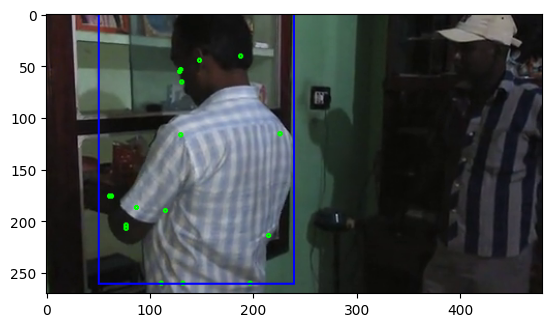

Label groceries, Score: 10000


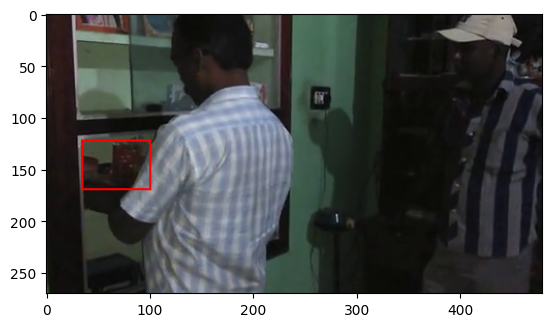

Label food, Score: 10000


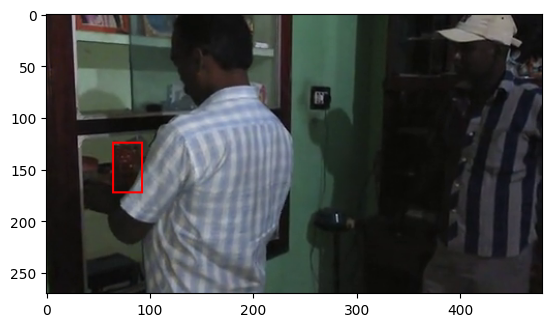

Label shelf, Score: 10000


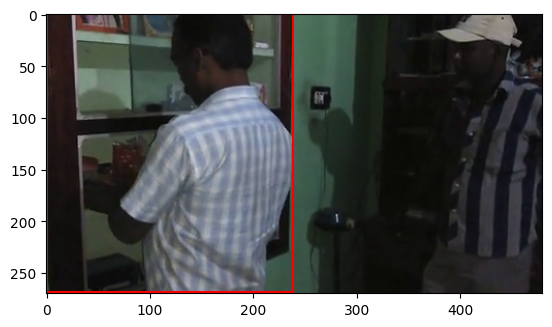

Label closet/cabinet, Score: 10000


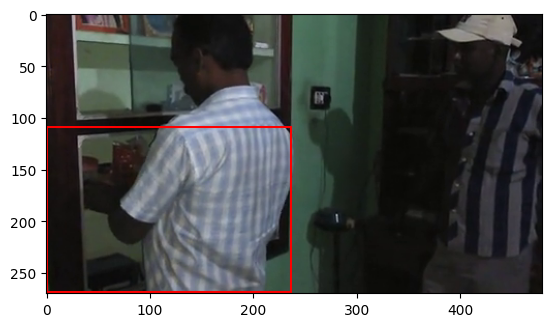

Label bag, Score: 10000


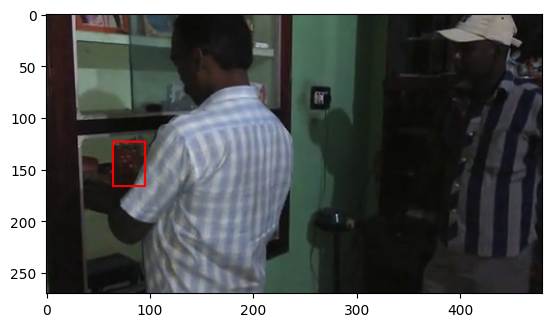

In [286]:
run_image_bbox_vis(img_out,
                       bboxes_gt,
                       per_keypoints_gt)

Label person, Score: 0.9961113333702087


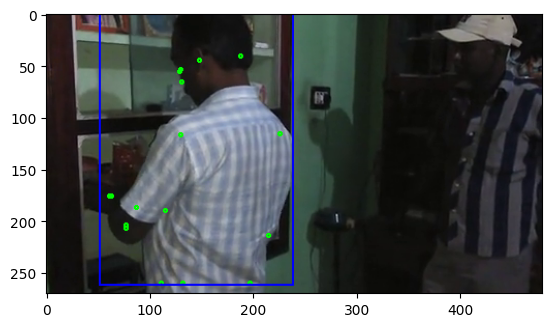

Label closet/cabinet, Score: 0.5173725485801697


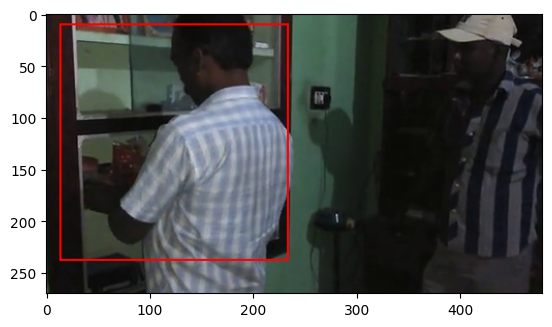

Label clothes, Score: 0.5993145108222961


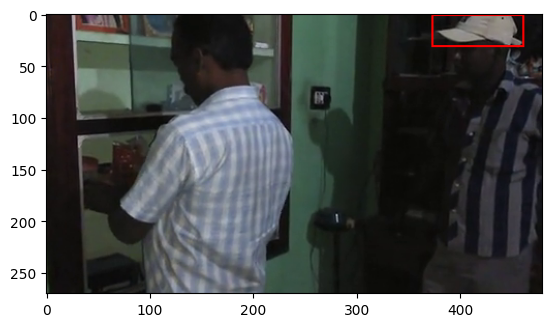

Label doorway, Score: 0.8604196310043335


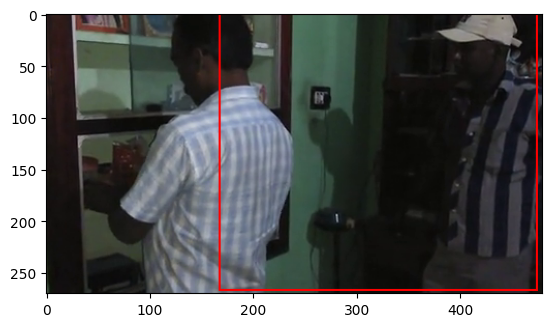

Label mirror, Score: 0.7590174674987793


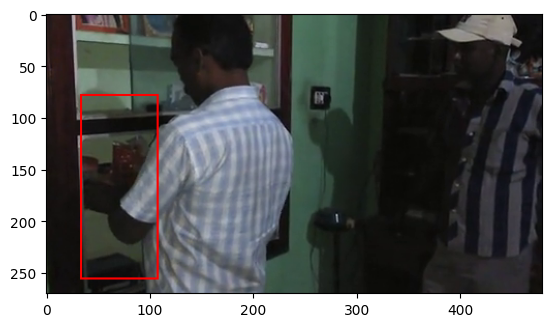

Label shelf, Score: 0.7285056710243225


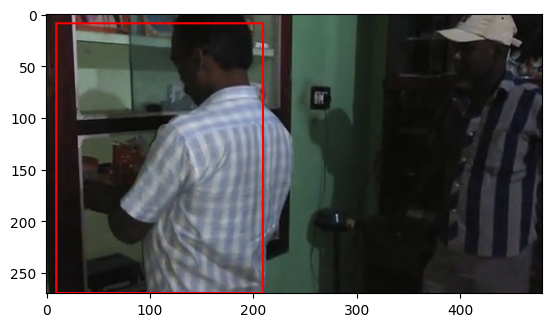

In [287]:
run_image_bbox_vis(img_out,
                       bboxes_pred,
                       per_keypoints_pred)

In [4]:
import numpy as np
np.set_printoptions(precision=4)
import copy
import torch

from dataloader.action_genome import AG, cuda_collate_fn

#from lib.config import Config
#from lib.evaluation_recall import BasicSceneGraphEvaluator
#from lib.object_detector import detector
#from lib.sttran import STTran

#conf = Config()
#for i in conf.args:
 #   print(i,':', conf.args[i])

AG_dataset = AG(mode="test", datasize='large', data_path='/data/dataset/charades/AG/', filter_nonperson_box_frame=True,
                filter_small_box=True)
dataloader = torch.utils.data.DataLoader(AG_dataset, shuffle=False, num_workers=0, collate_fn=cuda_collate_fn)


-------loading annotations---------slowly-----------
--------------------finish!-------------------------
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
There are 1737 videos and 54429 valid frames
48 videos are invalid (no person), remove them
20 videos are invalid (only one frame), remove them
8472 frames have no human bbox in GT, remove them!
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx


In [6]:
obj_bboxes_gt['001YG.mp4']['frames']

{'000264.png': [{'class': 'table',
   'bbox': (217.49999999999986,
    139.97619047619037,
    262.08333333333337,
    100.1214313241892),
   'attention_relationship': ['unsure'],
   'spatial_relationship': ['in_front_of'],
   'contacting_relationship': ['not_contacting'],
   'metadata': {'tag': '001YG.mp4/table/000264', 'set': 'train'},
   'visible': True},
  {'class': 'chair',
   'bbox': (48.00198412698421,
    174.31653069153066,
    193.7229744965878,
    95.68346930846936),
   'attention_relationship': ['not_looking_at'],
   'spatial_relationship': ['beneath', 'behind'],
   'contacting_relationship': ['sitting_on', 'leaning_on'],
   'metadata': {'tag': '001YG.mp4/chair/000264', 'set': 'train'},
   'visible': True}],
 '000093.png': [{'class': 'table',
   'bbox': (221.91847041847052,
    138.15205627705612,
    256.24999999999994,
    120.41666666666666),
   'attention_relationship': ['unsure'],
   'spatial_relationship': ['in_front_of'],
   'contacting_relationship': ['not_contacti

In [39]:
num_duplicate_obj_classes = 0
obj_labels_across_all_vids = []
for video_id in obj_bboxes_gt:
    for frame_id in obj_bboxes_gt[video_id]['frames']:
        obj_labels = [obj_struct['class'] for obj_struct in obj_bboxes_gt[video_id]['frames'][frame_id]]
        #print(len(obj_labels), obj_labels, set(obj_labels))
        if(len(obj_labels)>len(set(obj_labels))):
            num_duplicate_obj_classes+=1
        obj_labels_across_all_vids.extend(obj_labels)
        obj_labels_across_all_vids = list(set(obj_labels_across_all_vids))
        

In [41]:
len(obj_labels_across_all_vids)

35

In [43]:
dataloader.dataset.object_classes

37

In [14]:
st_out = pickle.load(open('/data/usrdata/shan/STTran_VG_charades_output/saved_preds.pkl','rb'))

In [15]:
data = st_out[0]
st_preds = st_out[1]
img_tensor, im_info, gt_boxes, num_boxes, data_index = data

In [16]:
or_video_id_frames = dataloader.dataset.video_list[data_index]
or_video_id = or_video_id_frames[0].split('/')[0]
or_video_id, or_video_id_frames

('1XOQ8.mp4',
 ['1XOQ8.mp4/000017.png',
  '1XOQ8.mp4/000025.png',
  '1XOQ8.mp4/000055.png',
  '1XOQ8.mp4/000077.png',
  '1XOQ8.mp4/000191.png',
  '1XOQ8.mp4/000212.png',
  '1XOQ8.mp4/000233.png',
  '1XOQ8.mp4/000234.png',
  '1XOQ8.mp4/000256.png',
  '1XOQ8.mp4/000272.png',
  '1XOQ8.mp4/000277.png',
  '1XOQ8.mp4/000278.png',
  '1XOQ8.mp4/000310.png',
  '1XOQ8.mp4/000321.png',
  '1XOQ8.mp4/000324.png',
  '1XOQ8.mp4/000369.png',
  '1XOQ8.mp4/000370.png',
  '1XOQ8.mp4/000399.png',
  '1XOQ8.mp4/000414.png'])

In [17]:
person_bboxes_gt[or_video_id]

{'frames': {'000017.png': {'bbox': array([[250.0486,   0.4854, 397.365 , 266.6172]], dtype=float32),
   'bbox_score': array([0.9687], dtype=float32),
   'bbox_size': (480, 270),
   'bbox_mode': 'xyxy',
   'keypoints': array([[[315.6162,  33.7097,   1.    ],
           [300.1092,  85.317 ,   1.    ],
           [293.3671,  85.317 ,   1.    ],
           [353.0352,  18.8684,   1.    ],
           [265.7242,   1.3286,   1.    ],
           [362.1372, 100.8329,   1.    ],
           [308.874 ,  97.4599,   1.    ],
           [366.1825, 214.5039,   1.    ],
           [260.3304, 223.9484,   1.    ],
           [353.3723,  72.1622,   1.    ],
           [273.4776, 128.1544,   1.    ],
           [347.9786, 252.2818,   1.    ],
           [292.3557, 251.2699,   1.    ],
           [360.4516, 214.5039,   1.    ],
           [297.7495, 204.7221,   1.    ],
           [379.3297, 265.774 ,   1.    ],
           [312.9193, 251.9445,   1.    ]]], dtype=float32),
   'keypoints_logits': array([[ 2.79

In [18]:
st_preds['boxes'].shape

torch.Size([143, 5])

In [19]:
torch.where(st_preds['boxes'][:,0] == 18)

(tensor([135, 136, 137, 138, 139, 140, 141, 142], device='cuda:0'),)

In [20]:
st_preds.keys()

dict_keys(['boxes', 'scores', 'distribution', 'pred_labels', 'features', 'fmaps', 'im_info', 'pred_scores', 'pair_idx', 'im_idx', 'human_idx', 'union_feat', 'union_box', 'spatial_masks', 'attention_distribution', 'spatial_distribution', 'contacting_distribution'])

In [21]:
st_preds['pair_idx'][torch.where(st_preds['pair_idx'][:,1]==17)]

tensor([[15, 17]], device='cuda:0')

In [22]:
st_preds['boxes'][15]

tensor([  2.0000, 151.5916,  50.2796, 391.6921, 265.5837], device='cuda:0')

In [23]:
st_preds['boxes'][0]

tensor([  0.0000, 245.7760,   0.0000, 397.9670, 263.7740], device='cuda:0')

In [24]:
set([int(im_id) for im_id in list(st_preds['im_idx'].cpu().clone().numpy())])

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18}

In [25]:
calculate_iou([0.9,0.8,112,121],[0,0,120,120])

0.9126199943491532

In [49]:
person_bboxes_pred = {}
obj_bboxes_pred = {}


def get_formatted_prediction(st_preds,
                             dataloader,
                             person_bboxes_pred, 
                             person_bboxes_gt, 
                             obj_bboxes_pred, 
                             obj_bboxes_gt,
                             obj_score_thresh = 0.5,
                             rel_att_thresh = 0.6,
                             rel_spatial_thresh = 0.6,
                             rel_contact_thresh = 0.6,
                            ):
    if(person_bboxes_pred is None):
        person_bboxes_pred = {}
    if(obj_bboxes_pred is None):
        obj_bboxes_pred = {}
        
        
    ##Person bboxes storage
    if or_video_id in person_bboxes_pred:
        print(f"ERROR: video id {or_video_id} already present in person_bboxes_pred dictionary")
        #continue
    if(or_video_id not in person_bboxes_gt):
        print(f"ERROR: video id {or_video_id} not found in person_bboxes_gt dictionary")
        #continue
    person_bboxes_pred[or_video_id] = {'frames':{}, 'vid_info':person_bboxes_gt[or_video_id]}

    for frame_i, vid_frame_id in enumerate(or_video_id_frames):
        frame_id = vid_frame_id.split('/')[-1]
        if(frame_id not in person_bboxes_gt[or_video_id]['frames']):
            print(f"ERROR: frame id {frame_id} not found in person_bboxes_gt dictionary")
            continue

        person_idx = st_preds['human_idx'][frame_i]
        bbox_coords = st_preds['boxes'][person_idx].cpu().clone().numpy()[0][1:]#[1:]
        bbox_score = st_preds['pred_scores'][person_idx].cpu().clone().numpy()
        bbox_label = dataloader.dataset.object_classes[st_preds['pred_labels'][person_idx]]
        if(bbox_label not in ['person']):
            print(f"ERROR: for frame id {frame_id}, detected bbox_label for person is {bbox_label} and not 'person'")
        #print(bbox_coords.shape)
        person_bboxes_pred[or_video_id]['frames'][frame_id] = {'bbox': bbox_coords, 
                                                  'bbox_score': bbox_score,
                                                  'bbox_obj_label':bbox_label,
                                                  'bbox_size': person_bboxes_gt[or_video_id]['frames'][frame_id]['bbox_size'],
                                                  'keypoints': person_bboxes_gt[or_video_id]['frames'][frame_id]['keypoints'],
                                                  'keypoints_logits': person_bboxes_gt[or_video_id]['frames'][frame_id]['keypoints_logits'],

                                                 }


    ##Obj bboxes storage
    if or_video_id in obj_bboxes_pred:
        print(f"ERROR: video id {or_video_id} already present in obj_bboxes_pred dictionary")
        #continue
    if(or_video_id not in obj_bboxes_gt):
        print(f"ERROR: video id {or_video_id} not found in obj_bboxes_gt dictionary")
        #continue
    obj_bboxes_pred[or_video_id] = {'frames':{}, 'vid_info':obj_bboxes_gt[or_video_id]}
    assert(st_preds['im_idx'].size(0)==st_preds['pair_idx'].size(0))

    image_idx_ints = set([int(im_id) for im_id in list(st_preds['im_idx'].cpu().clone().numpy())])
    for frame_i in image_idx_ints: #
        frame_i = int(frame_i)
        or_vid_frame_id = or_video_id_frames[frame_i]
        or_frame_id = or_vid_frame_id.split('/')[-1]
        #print(or_frame_id, obj_bboxes_pred[or_video_id]['frames'].keys())
        #input()
        if(or_frame_id not in obj_bboxes_gt[or_video_id]['frames']):
            print(f"WARNING: frame id {frame_id} not found in obj_bboxes_gt dictionary")

        if(or_frame_id not in obj_bboxes_pred[or_video_id]['frames']):
            obj_bboxes_pred[or_video_id]['frames'][or_frame_id] = []
        #else:
         #   print(f"Warning: frame id {or_frame_id} already found in obj_bboxes_pred dictionary")

        objs_id_for_frame = torch.where(st_preds['boxes'][:,0]==frame_i)[0]
        if(len(objs_id_for_frame)<=0):
            print(f"WARNING: found 0 objs for original frame id {frame_id} (original frame id:)")
        human_obj_idx = int(st_preds['human_idx'][frame_i][0])
        #print('obj_ids', objs_id_for_frame)
        #input()
        obj_labels_covered_with_conf_and_listposition = {} #maintain objects already instantiated for the frame
        for idx in objs_id_for_frame:
            #print('hello', idx)
            #input()
            idx=int(idx)
            #idx_int = int(idx)
            if(idx==human_obj_idx):
                print(f"ignoring obj id {idx} as it is human index")
                continue
            #print('ABC', idx)

            obj_bbox = st_preds['boxes'][idx].cpu().clone().numpy()[1:]#[1:]
            obj_bbox[2] = obj_bbox[2] - obj_bbox[0]
            obj_bbox[3] = obj_bbox[3] - obj_bbox[1]
            obj_bbox_score = st_preds['pred_scores'][idx].unsqueeze(-1).cpu().clone().numpy()
            obj_bbox_label = dataloader.dataset.object_classes[st_preds['pred_labels'][idx]]
            
            if(obj_bbox_score[0]<obj_score_thresh):
                print(f"WARNING: Skipping obj {obj_bbox_label} with bbox score {obj_bbox_score[0]} as < thresh {obj_score_thresh}")
                continue

            if(obj_bbox_label in obj_labels_covered_with_conf_and_listposition):
                already_existing_obj_score_and_listposition = obj_labels_covered_with_conf_and_listposition[obj_bbox_label]
                if(float(obj_bbox_score[0])> already_existing_obj_score_and_listposition[0]):
                    print(f"WARNING: Replacing existing obj label {obj_bbox_label} with lower bbox score {already_existing_obj_score_and_listposition[0]} as new one has higher score {obj_bbox_score[0]}")
                    obj_bboxes_pred[or_video_id]['frames'][or_frame_id].pop(already_existing_obj_score_and_listposition[1])
                    obj_labels_covered_with_conf_and_listposition[obj_bbox_label] = (float(obj_bbox_score[0]), len(obj_bboxes_pred[or_video_id]['frames'][or_frame_id]))
                else:
                    print(f"WARNING: Skipping obj {obj_bbox_label} with bbox score {obj_bbox_score[0]} as < already existing obj label {obj_bbox_label} with score {already_existing_obj_score_and_listposition[0]}")
                    continue
            else:
                obj_labels_covered_with_conf_and_listposition[obj_bbox_label] = (float(obj_bbox_score[0]), len(obj_bboxes_pred[or_video_id]['frames'][or_frame_id]))
            obj_struct = {'class': obj_bbox_label,
                          'obj_score': obj_bbox_score,
                           'bbox': tuple(obj_bbox),
                           'attention_relationship': [],
                           'attention_relationship_scores': [],
                           'spatial_relationship': [],
                          'spatial_relationship_scores': [],
                           'contacting_relationship': [],
                          'contacting_relationship_scores': [],
                          'metadata': None,
                           #'metadata': {'tag': '1X0M3.mp4/groceries/000523', 'set': 'train'},
                           'visible': True}
            rels_ids = torch.where(st_preds['pair_idx'][:,1]==idx)
            att_rel_distrb = st_preds['attention_distribution'][rels_ids][0]

            for rel_i, rel_score in enumerate(att_rel_distrb):
                if(rel_score>=rel_att_thresh):
                    rel_name = dataloader.dataset.attention_relationships[rel_i]
                    obj_struct['attention_relationship'].append(rel_name)
                    obj_struct['attention_relationship_scores'].append(float(rel_score))

            spatial_rel_distrb = st_preds['spatial_distribution'][rels_ids][0]
            for rel_i, rel_score in enumerate(spatial_rel_distrb):
                if(rel_score>=rel_spatial_thresh):
                    rel_name = dataloader.dataset.spatial_relationships[rel_i]
                    obj_struct['spatial_relationship'].append(rel_name)
                    obj_struct['spatial_relationship_scores'].append(float(rel_score))
            contact_rel_distrb = st_preds['contacting_distribution'][rels_ids][0]
            for rel_i, rel_score in enumerate(contact_rel_distrb):
                if(rel_score>=rel_contact_thresh):
                    rel_name = dataloader.dataset.contacting_relationships[rel_i]
                    obj_struct['contacting_relationship'].append(rel_name)
                    obj_struct['contacting_relationship_scores'].append(float(rel_score))

            obj_bboxes_pred[or_video_id]['frames'][or_frame_id].append(obj_struct)
            
    return person_bboxes_pred, obj_bboxes_pred

In [50]:
person_bboxes_pred,obj_bboxes_pred = get_formatted_prediction(st_preds = st_preds,
                         dataloader = dataloader,
                         person_bboxes_pred=None, 
                         person_bboxes_gt = person_bboxes_gt, 
                         obj_bboxes_pred = None, 
                         obj_bboxes_gt = obj_bboxes_gt,
                        )

ignoring obj id 0 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 15 as it is human index
ignoring obj id 22 as it is human index
ignoring obj id 27 as it is human index
ignoring obj id 38 as it is human index
ignoring obj id 45 as it is human index
ignoring obj id 58 as it is human index
ignoring obj id 68 as it is human index
ignoring obj id 73 as it is human index
ignoring obj id 80 as it is human index
ignoring obj id 87 as it is human index
ignoring obj id 93 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 111 as it is human index
ignoring obj id 116 as it is human index
ignoring obj id 120 as it is human index
ignoring obj id 127 as it is human index
ignoring obj id 135 as it is human index


In [31]:
obj_bboxes_gt['1XOQ8.mp4']['frames']['000017.png']

[{'class': 'floor',
  'bbox': None,
  'attention_relationship': None,
  'spatial_relationship': None,
  'contacting_relationship': None,
  'metadata': {'tag': '1XOQ8.mp4/floor/000017', 'set': 'test'},
  'visible': False},
 {'class': 'closet/cabinet',
  'bbox': (112.50000000000003, 0.0, 183.23957561544725, 269.3858748511248),
  'attention_relationship': ['looking_at'],
  'spatial_relationship': ['in_front_of', 'on_the_side_of'],
  'contacting_relationship': ['not_contacting'],
  'metadata': {'tag': '1XOQ8.mp4/closet_cabinet/000017', 'set': 'test'},
  'visible': True},
 {'class': 'shoe',
  'bbox': None,
  'attention_relationship': None,
  'spatial_relationship': None,
  'contacting_relationship': None,
  'metadata': {'tag': '1XOQ8.mp4/shoe/000017', 'set': 'test'},
  'visible': False}]

In [30]:
obj_bboxes_pred

{'1XOQ8.mp4': {'frames': {'000017.png': [{'class': 'doorway',
     'obj_score': array([0.2727], dtype=float32),
     'bbox': (204.11414, 0.0, 264.15533, 269.55),
     'attention_relationship': ['not_looking_at', 'unsure'],
     'attention_relationship_scores': [1.826707124710083, 0.9285533428192139],
     'spatial_relationship': ['on_the_side_of', 'in'],
     'spatial_relationship_scores': [0.9904967546463013, 0.9999992847442627],
     'contacting_relationship': ['holding', 'not_contacting'],
     'contacting_relationship_scores': [0.8680537939071655, 1.0],
     'metadata': None,
     'visible': True},
    {'class': 'closet/cabinet',
     'obj_score': array([0.9188], dtype=float32),
     'bbox': (166.71593, 0.022412108, 291.8615, 269.5276),
     'attention_relationship': [],
     'attention_relationship_scores': [],
     'spatial_relationship': ['in_front_of', 'on_the_side_of'],
     'spatial_relationship_scores': [0.9975205063819885, 1.0],
     'contacting_relationship': ['holding', '

In [31]:
person_bboxes_pred

{'1XOQ8.mp4': {'frames': {'000017.png': {'bbox': array([245.776,   0.   , 397.967, 263.774], dtype=float32),
    'bbox_score': array([0.9501], dtype=float32),
    'bbox_obj_label': 'person',
    'bbox_size': (480, 270),
    'keypoints': array([[[315.6162,  33.7097,   1.    ],
            [300.1092,  85.317 ,   1.    ],
            [293.3671,  85.317 ,   1.    ],
            [353.0352,  18.8684,   1.    ],
            [265.7242,   1.3286,   1.    ],
            [362.1372, 100.8329,   1.    ],
            [308.874 ,  97.4599,   1.    ],
            [366.1825, 214.5039,   1.    ],
            [260.3304, 223.9484,   1.    ],
            [353.3723,  72.1622,   1.    ],
            [273.4776, 128.1544,   1.    ],
            [347.9786, 252.2818,   1.    ],
            [292.3557, 251.2699,   1.    ],
            [360.4516, 214.5039,   1.    ],
            [297.7495, 204.7221,   1.    ],
            [379.3297, 265.774 ,   1.    ],
            [312.9193, 251.9445,   1.    ]]], dtype=float32),
 

In [17]:
st_preds['boxes'] = st_preds['boxes']

In [18]:
st_preds['pair_idx'][torch.where(st_preds['pair_idx'][:,1]==17)]

tensor([[15, 17]], device='cuda:0')

In [29]:
st_preds['attention_distribution'][torch.where(st_preds['pair_idx'][:,1]==17)]

tensor([[ 0.1819,  1.3126, -0.3731]], device='cuda:0')

In [19]:
assert(st_preds['im_idx'].size(0)==st_preds['pair_idx'].size(0))
st_preds['im_idx']

tensor([ 0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  2.,
         2.,  2.,  2.,  2.,  2.,  3.,  3.,  3.,  3.,  4.,  4.,  4.,  4.,  4.,
         4.,  4.,  4.,  4.,  4.,  5.,  5.,  5.,  5.,  5.,  5.,  6.,  6.,  6.,
         6.,  6.,  6.,  6.,  6.,  6.,  6.,  6.,  6.,  7.,  7.,  7.,  7.,  7.,
         7.,  7.,  7.,  7.,  8.,  8.,  8.,  8.,  9.,  9.,  9.,  9.,  9.,  9.,
        10., 10., 10., 10., 10., 10., 11., 11., 11., 11., 11., 12., 12., 12.,
        12., 12., 12., 12., 13., 13., 13., 13., 13., 13., 13., 13., 13., 14.,
        14., 14., 14., 15., 15., 15., 16., 16., 16., 16., 16., 16., 17., 17.,
        17., 17., 17., 17., 17., 18., 18., 18., 18., 18., 18., 18.],
       device='cuda:0')

In [1]:
st_preds.keys()#['spat'][0]

NameError: name 'st_preds' is not defined

In [27]:
st_preds['im_idx'][0]

tensor(0., device='cuda:0')

ERROR: video id 1XOQ8.mp4 already present in obj_bboxes_pred dictionary
ignoring obj id 0 as it is human index
ignoring obj id 0 as it is human index
ignoring obj id 0 as it is human index
ignoring obj id 0 as it is human index
ignoring obj id 0 as it is human index
ignoring obj id 0 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 7 as it is human index
ignoring obj id 15 as it is human index
ignoring obj id 15 as it is human index
ignoring obj id 15 as it is human index
ignoring obj id 15 as it is human index
ignoring obj id 15 as it is human index
ignoring obj id 15 as it is human index
ignoring obj id 22 as it is human index
ignoring obj id 22 as it is human index
ignoring obj id 22 as it is human index
ignoring obj id 22 as it is human index
ignoring obj id 27 as

ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 101 as it is human index
ignoring obj id 111 as it is human index
ignoring obj id 111 as it is human index
ignoring obj id 111 as it is human index
ignoring obj id 111 as it is human index
ignoring obj id 116 as it is human index
ignoring obj id 116 as it is human index
ignoring obj id 116 as it is human index
ignoring obj id 120 as it is human index
ignoring obj id 120 as it is human index
ignoring obj id 120 as it is human index
ignoring obj id 120 as it is human index
ignoring obj id 120 as it is human index
ignoring obj id 120 as it is human index
ignoring obj id 127 as it is human index
ignoring obj id 127 as it is human index
ignoring obj id 

In [35]:
st_preds['boxes'][1].cpu().clone().numpy()[1:]

array([204.1141,   0.    , 468.2695, 269.55  ], dtype=float32)

In [21]:
rels_ids = torch.where(st_preds['pair_idx'][:,1]==4)
att_rel_distrb = st_preds['attention_distribution'][rels_ids]

In [23]:
att_rel_distrb

tensor([-1.7695, -1.7233,  2.6515], device='cuda:0')

In [24]:
dataloader.dataset.attention_relationships

['looking_at', 'not_looking_at', 'unsure']

In [22]:
st_preds['boxes']

tensor([[0.0000e+00, 2.4578e+02, 0.0000e+00, 3.9797e+02, 2.6377e+02],
        [0.0000e+00, 2.0411e+02, 0.0000e+00, 4.6827e+02, 2.6955e+02],
        [0.0000e+00, 1.6672e+02, 2.2412e-02, 4.5858e+02, 2.6955e+02],
        [0.0000e+00, 1.0573e+02, 3.2363e+00, 3.0139e+02, 2.6955e+02],
        [0.0000e+00, 2.0830e+02, 4.8750e+01, 2.5714e+02, 1.7842e+02],
        [0.0000e+00, 3.6687e+02, 0.0000e+00, 4.7860e+02, 2.6679e+02],
        [0.0000e+00, 1.7641e+02, 1.6841e+02, 2.3130e+02, 2.6955e+02],
        [1.0000e+00, 1.9671e+02, 1.2905e+01, 3.7947e+02, 2.6464e+02],
        [1.0000e+00, 1.0721e+02, 0.0000e+00, 4.1321e+02, 2.7039e+02],
        [1.0000e+00, 1.7426e+02, 1.7458e+02, 2.3895e+02, 2.7414e+02],
        [1.0000e+00, 1.0451e+02, 0.0000e+00, 3.2324e+02, 2.7730e+02],
        [1.0000e+00, 1.2761e+02, 4.0711e+00, 2.5866e+02, 2.7895e+02],
        [1.0000e+00, 3.6769e+02, 0.0000e+00, 4.7840e+02, 2.6337e+02],
        [1.0000e+00, 3.6296e+02, 4.5605e+00, 4.8044e+02, 2.6535e+02],
        [1.0000e+00,

In [25]:
len(torch.where(st_preds['boxes'][:,0]==0)[0])

7

In [ ]:
st_preds['pair_idx'][torch.where(st_preds['pair_idx'][:,1]==17)]

In [ ]:
st_preds['im_idx']

In [59]:
obj_bboxes_gt['1X0M3.mp4']['frames']#['vid_info'], person_bboxes_gt['1X0M3.mp4']['vid_info']#['frames']#[0]#['vid_info']

{'000523.png': [{'class': 'groceries',
   'bbox': (198.29166666666652,
    217.16071428571436,
    56.24999999999994,
    52.83928571428564),
   'attention_relationship': ['not_looking_at'],
   'spatial_relationship': ['on_the_side_of'],
   'contacting_relationship': ['not_contacting'],
   'metadata': {'tag': '1X0M3.mp4/groceries/000523', 'set': 'train'},
   'visible': True}],
 '000485.png': [{'class': 'groceries',
   'bbox': (217.75520946373916,
    153.20833333333331,
    47.494790536260766,
    54.00000038599435),
   'attention_relationship': ['not_looking_at'],
   'spatial_relationship': ['in_front_of'],
   'contacting_relationship': ['holding'],
   'metadata': {'tag': '1X0M3.mp4/groceries/000485', 'set': 'train'},
   'visible': True}],
 '000600.png': [{'class': 'groceries',
   'bbox': (192.9583333333332,
    246.1666666666665,
    58.342013888888886,
    23.833333333333485),
   'attention_relationship': ['not_looking_at'],
   'spatial_relationship': ['on_the_side_of'],
   'contact

In [32]:
dataloader.dataset.object_classes[st_preds['pred_labels'][0]]

'person'

In [31]:
a.unsqueeze(-1).cpu().clone().numpy()

array([0.9501], dtype=float32)

In [11]:
dataloader.dataset.object_classes

['__background__',
 'person',
 'bag',
 'bed',
 'blanket',
 'book',
 'box',
 'broom',
 'chair',
 'closet/cabinet',
 'clothes',
 'cup/glass/bottle',
 'dish',
 'door',
 'doorknob',
 'doorway',
 'floor',
 'food',
 'groceries',
 'laptop',
 'light',
 'medicine',
 'mirror',
 'paper/notebook',
 'phone/camera',
 'picture',
 'pillow',
 'refrigerator',
 'sandwich',
 'shelf',
 'shoe',
 'sofa/couch',
 'table',
 'television',
 'towel',
 'vacuum',
 'window']

In [10]:
st_preds.keys()

dict_keys(['boxes', 'scores', 'distribution', 'pred_labels', 'features', 'fmaps', 'im_info', 'pred_scores', 'pair_idx', 'im_idx', 'human_idx', 'union_feat', 'union_box', 'spatial_masks', 'attention_distribution', 'spatial_distribution', 'contacting_distribution'])

In [48]:
per_bboxes_gt['001YG.mp4']['frames']['000089.png']#['vid_info']

{'bbox': array([[ 24.2977,  71.444 , 259.236 , 268.2029]], dtype=float32),
 'bbox_score': array([0.9961], dtype=float32),
 'bbox_size': (480, 270),
 'bbox_mode': 'xyxy',
 'keypoints': array([[[149.5195, 120.5493,   1.    ],
         [146.4859, 111.437 ,   1.    ],
         [141.0927, 115.8244,   1.    ],
         [111.7676, 123.5868,   1.    ],
         [112.4417, 124.2617,   1.    ],
         [ 82.1054, 154.6362,   1.    ],
         [113.4529, 168.4734,   1.    ],
         [153.5644, 207.9602,   1.    ],
         [162.6653, 247.447 ,   1.    ],
         [146.4859, 149.9113,   1.    ],
         [216.5966, 229.2223,   1.    ],
         [112.1047, 243.7346,   1.    ],
         [163.3394, 267.6966,   1.    ],
         [237.832 , 202.5603,   1.    ],
         [239.1803, 202.5603,   1.    ],
         [186.9344, 219.0975,   1.    ],
         [220.9785, 227.8723,   1.    ]]], dtype=float32),
 'keypoints_logits': array([[11.0734, 10.5785, 10.8634,  3.6264, 11.4512,  4.5003,  6.4191,
          

In [81]:
obj_bboxes_gt['001YG.mp4']['frames']

#vid_id
    #frames
        #frame_png_key
            #objs_list #(each has:)
                #'class': 
                #'bbox': (x1,y1,w,h)
                #'attention_relationship': []
                #'spatial_relationship': [],
                #'contacting_relationship':[]
                #'metadata': {'tag'}
                #'visible': True/False
    """
    [{'class': 'table',
  'bbox': (222.10317460317458,
   143.829365079365,
   257.77777777777777,
   101.11111111111109),
  'attention_relationship': ['unsure'],
  'spatial_relationship': ['in_front_of'],
  'contacting_relationship': ['not_contacting'],
  'metadata': {'tag': '001YG.mp4/table/000089', 'set': 'train'},
  'visible': True},
 {'class': 'chair',
  'bbox': (56.34126984126985,
   179.16666666666663,
   192.77777777777777,
   90.56890211160798),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['beneath', 'behind'],
  'contacting_relationship': ['sitting_on', 'leaning_on'],
  'metadata': {'tag': '001YG.mp4/chair/000089', 'set': 'train'},
  'visible': True}]a
    """
    #vid_info
        #resolution
        #num_total_frames
        #num_salient_frames
    #

179

In [80]:
56/19

2.9473684210526314

In [9]:
st_out[1]['pred_scores']#.shape

tensor([0.9501, 0.2727, 0.9188, 0.8122, 0.7126, 0.5744, 0.9581, 0.9889, 0.3020,
        0.6038, 0.7784, 0.4551, 0.4296, 0.4847, 0.6746, 0.9899, 0.6690, 0.4590,
        0.5015, 0.4711, 0.7909, 0.6892, 0.9370, 0.7714, 0.6570, 0.9493, 0.6341,
        0.9907, 0.7859, 0.8857, 0.7780, 0.7181, 0.8582, 0.3781, 0.5874, 0.5643,
        0.3483, 0.3000, 0.9555, 0.7137, 0.8785, 0.8207, 0.7550, 0.3467, 0.3525,
        0.9973, 0.6976, 0.6333, 0.6093, 0.8402, 0.5195, 0.4312, 0.3335, 0.6707,
        0.3205, 0.3191, 0.9763, 0.3880, 0.9969, 0.4521, 0.6216, 0.3591, 0.8649,
        0.4368, 0.5845, 0.3864, 0.9859, 0.9369, 0.9993, 0.6415, 0.4152, 0.9846,
        0.4944, 0.9992, 0.5217, 0.6505, 0.4403, 0.5667, 0.9926, 0.7417, 0.9971,
        0.6103, 0.4693, 0.9619, 0.4660, 0.5817, 0.6358, 0.9988, 0.6729, 0.4523,
        0.9599, 0.4646, 0.9168, 0.9988, 0.2460, 0.3504, 0.7469, 0.4045, 0.5282,
        0.9447, 0.9301, 0.9988, 0.3112, 0.5780, 0.4364, 0.4694, 0.8872, 0.4371,
        0.8066, 0.7276, 0.7147, 0.9991, 

('1XOQ8.mp4',
 ['1XOQ8.mp4/000017.png',
  '1XOQ8.mp4/000025.png',
  '1XOQ8.mp4/000055.png',
  '1XOQ8.mp4/000077.png',
  '1XOQ8.mp4/000191.png',
  '1XOQ8.mp4/000212.png',
  '1XOQ8.mp4/000233.png',
  '1XOQ8.mp4/000234.png',
  '1XOQ8.mp4/000256.png',
  '1XOQ8.mp4/000272.png',
  '1XOQ8.mp4/000277.png',
  '1XOQ8.mp4/000278.png',
  '1XOQ8.mp4/000310.png',
  '1XOQ8.mp4/000321.png',
  '1XOQ8.mp4/000324.png',
  '1XOQ8.mp4/000369.png',
  '1XOQ8.mp4/000370.png',
  '1XOQ8.mp4/000399.png',
  '1XOQ8.mp4/000414.png'])

In [ ]:
person_bboxes_pred = {}
obj_bboxes_pred = {}

for frame_id in preds['im_idx']:
    im_idx = int(frame_id)
    if(or_video_id not in person_bboxes_pred):
        person_bboxes_pred

In [34]:
preds['im_idx']

tensor([ 0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  2.,
         2.,  2.,  2.,  2.,  2.,  3.,  3.,  3.,  3.,  4.,  4.,  4.,  4.,  4.,
         4.,  4.,  4.,  4.,  4.,  5.,  5.,  5.,  5.,  5.,  5.,  6.,  6.,  6.,
         6.,  6.,  6.,  6.,  6.,  6.,  6.,  6.,  6.,  7.,  7.,  7.,  7.,  7.,
         7.,  7.,  7.,  7.,  8.,  8.,  8.,  8.,  9.,  9.,  9.,  9.,  9.,  9.,
        10., 10., 10., 10., 10., 10., 11., 11., 11., 11., 11., 12., 12., 12.,
        12., 12., 12., 12., 13., 13., 13., 13., 13., 13., 13., 13., 13., 14.,
        14., 14., 14., 15., 15., 15., 16., 16., 16., 16., 16., 16., 17., 17.,
        17., 17., 17., 17., 17., 18., 18., 18., 18., 18., 18., 18.],
       device='cuda:0')

In [41]:
preds['pred_scores'].shape, preds['boxes'].shape, preds['scores'].shape

(torch.Size([143]), torch.Size([143, 5]), torch.Size([198]))

In [23]:
preds['pred_labels'][1]

tensor(15, device='cuda:0')

In [24]:
dataloader.dataset.object_classes

'doorway'

In [33]:
dataloader.dataset.spatial_relationships

['above', 'beneath', 'in_front_of', 'behind', 'on_the_side_of', 'in']

In [29]:
preds['contacting_distribution'].shape

torch.Size([124, 17])

In [15]:
preds['attention_distribution'].shape

torch.Size([124, 3])

In [32]:
preds['spatial_distribution'].shape

torch.Size([124, 6])

In [49]:
preds['boxes'].shape

torch.Size([143, 5])

In [54]:
preds['spatial_masks'].shape

torch.Size([124, 2, 27, 27])

In [55]:
preds['pred_labels'].shape

torch.Size([143])

torch.Size([116])

In [51]:
preds.keys()

dict_keys(['boxes', 'scores', 'distribution', 'pred_labels', 'features', 'fmaps', 'im_info', 'pred_scores', 'pair_idx', 'im_idx', 'human_idx', 'union_feat', 'union_box', 'spatial_masks', 'attention_distribution', 'spatial_distribution', 'contacting_distribution'])

In [11]:
preds['human_idx']

tensor([[  0],
        [  7],
        [ 15],
        [ 22],
        [ 27],
        [ 38],
        [ 45],
        [ 58],
        [ 68],
        [ 73],
        [ 80],
        [ 87],
        [ 93],
        [101],
        [111],
        [116],
        [120],
        [127],
        [135]], device='cuda:0')

In [20]:
preds['boxes']

tensor([[0.0000e+00, 2.4578e+02, 0.0000e+00, 3.9797e+02, 2.6377e+02],
        [0.0000e+00, 2.0411e+02, 0.0000e+00, 4.6827e+02, 2.6955e+02],
        [0.0000e+00, 1.6672e+02, 2.2412e-02, 4.5858e+02, 2.6955e+02],
        [0.0000e+00, 1.0573e+02, 3.2363e+00, 3.0139e+02, 2.6955e+02],
        [0.0000e+00, 2.0830e+02, 4.8750e+01, 2.5714e+02, 1.7842e+02],
        [0.0000e+00, 3.6687e+02, 0.0000e+00, 4.7860e+02, 2.6679e+02],
        [0.0000e+00, 1.7641e+02, 1.6841e+02, 2.3130e+02, 2.6955e+02],
        [1.0000e+00, 1.9671e+02, 1.2905e+01, 3.7947e+02, 2.6464e+02],
        [1.0000e+00, 1.0721e+02, 0.0000e+00, 4.1321e+02, 2.7039e+02],
        [1.0000e+00, 1.7426e+02, 1.7458e+02, 2.3895e+02, 2.7414e+02],
        [1.0000e+00, 1.0451e+02, 0.0000e+00, 3.2324e+02, 2.7730e+02],
        [1.0000e+00, 1.2761e+02, 4.0711e+00, 2.5866e+02, 2.7895e+02],
        [1.0000e+00, 3.6769e+02, 0.0000e+00, 4.7840e+02, 2.6337e+02],
        [1.0000e+00, 3.6296e+02, 4.5605e+00, 4.8044e+02, 2.6535e+02],
        [1.0000e+00,

In [16]:
preds['boxes'][135]#[10]

tensor([ 18.0000, 209.2979,   5.5446, 423.8618, 253.7459], device='cuda:0')

In [21]:
frame_wise_bboxes = {}
for pred_box in preds['boxes']:
    frame_n = int(pred_box[0])
    if(frame_n not in frame_wise_bboxes):
        frame_wise_bboxes[frame_n] = []
    frame_wise_bboxes[frame_n].append(pred_box[1:])

In [33]:
frame_wise_bboxes[1][0].cpu().numpy()

array([196.7141,  12.9046, 379.4674, 264.6427], dtype=float32)

In [35]:
[('person', tens.cpu().numpy()) for tens in frame_wise_bboxes[1]]

[('person', array([196.7141,  12.9046, 379.4674, 264.6427], dtype=float32)),
 ('person', array([107.2131,   0.    , 413.2126, 270.3894], dtype=float32)),
 ('person', array([174.2577, 174.5781, 238.9534, 274.1385], dtype=float32)),
 ('person', array([104.5133,   0.    , 323.2363, 277.2957], dtype=float32)),
 ('person', array([127.6082,   4.0711, 258.6595, 278.9526], dtype=float32)),
 ('person', array([367.6871,   0.    , 478.403 , 263.3732], dtype=float32)),
 ('person', array([362.9597,   4.5605, 480.4442, 265.3461], dtype=float32)),
 ('person', array([173.6256, 153.7208, 244.1615, 270.0696], dtype=float32))]

In [25]:
frames = get_video_frames('/data/dataset/charades/video/Charades_v1_480/1XOQ8.mp4')

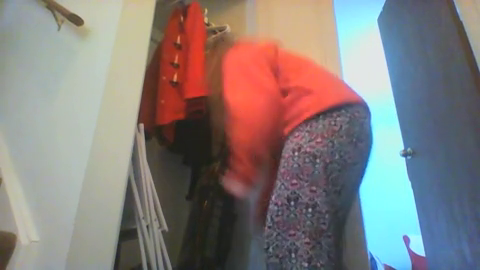

In [26]:
pil_img = frames[25]
pil_img

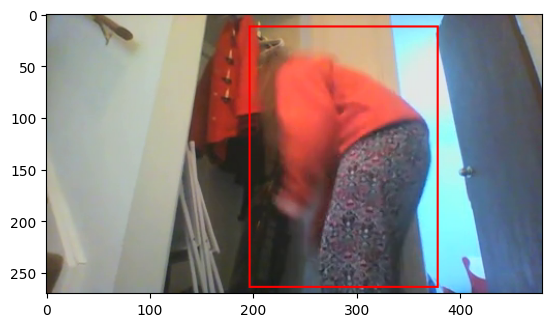

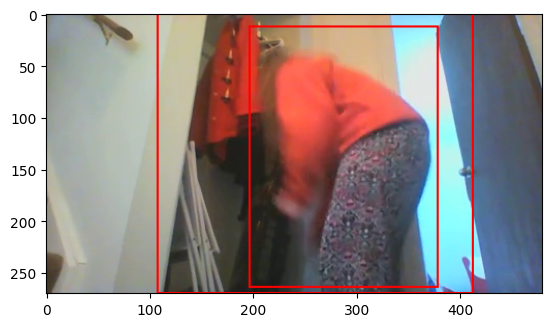

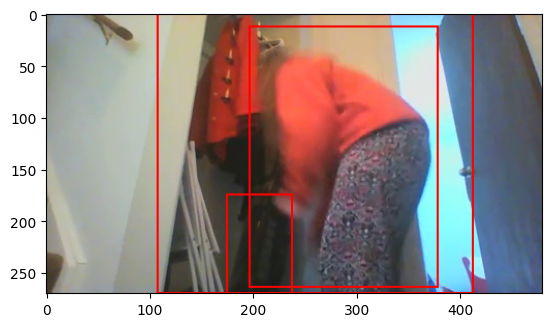

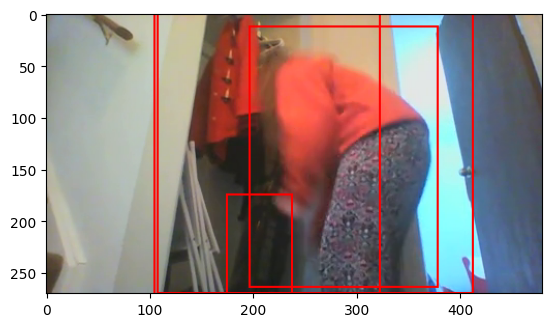

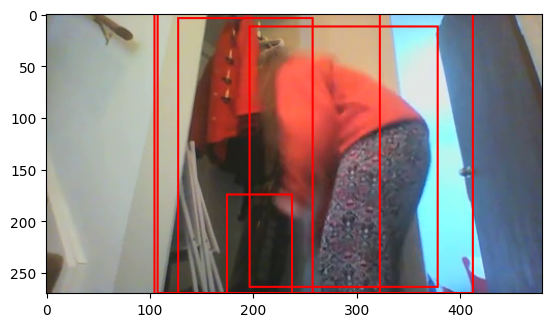

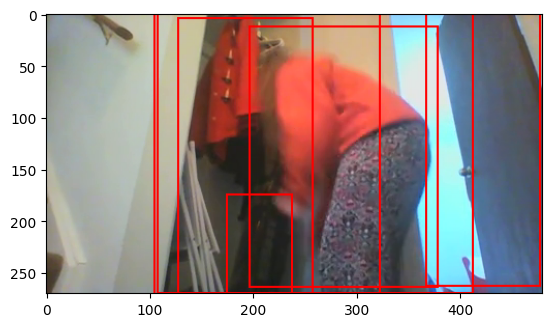

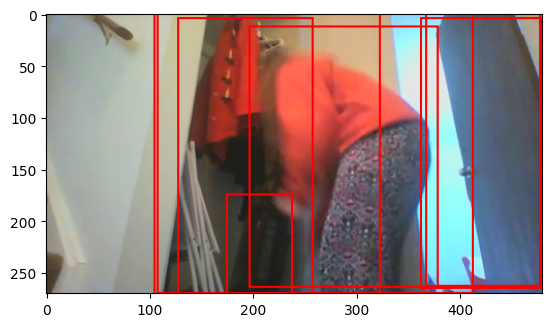

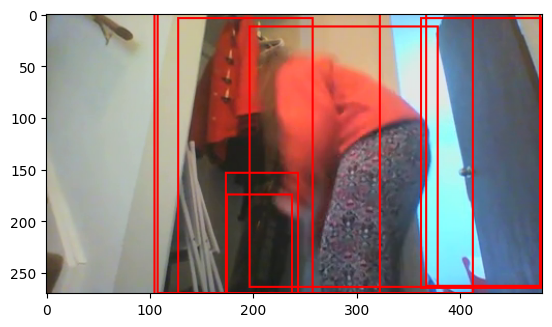

In [37]:
from PIL import Image, ImageDraw
highlight_size = 2
highlight_color = (0, 255, 0)  # Red color in RGB format

bboxes = [('person', tens.cpu().numpy()) for tens in frame_wise_bboxes[1]]

og_img = pil_img
for item in bboxes:
    bbox=item[1]
    #bbox = [ 10.825662 ,   6.1736574, 122.91022  , 234.68478  ]#obj_info['bbox'].tolist()#[178.9430, 429.4745, 412.0135, 555.8653]
    #print(bbox)
    # Create a drawing context
    draw = ImageDraw.Draw(og_img)
    [x,y,w,h] = bbox
        
    if(item[0] in ['person']): 
        #continue
        
        bbox_coord = bbox#[x, y, x+w, y+h]
        draw.rectangle(bbox_coord, outline="red", width=2)  # You can customize the outline color and widt
        #for kframe in keyframes:
         #   x_k, y_k = kframe[0], kframe[1]
            # Draw a circle at the specified coordinate to highlight the keypoint
          #  draw.ellipse([(x_k - highlight_size, y_k - highlight_size), (x_k + highlight_size, y_k + highlight_size)], outline=highlight_color, width=2)
           # draw.rectangle(bbox_coord, outline="blue", width=2)  # You can customize the outline color and width

    else:
        bbox_coord = [x, y, x+w, y+h]
        draw.rectangle(bbox_coord, outline="red", width=2)  # You can customize the outline color and width
    plt.imshow(og_img)
    plt.show()  
    
    #plt.imshow(og_img)
        #print(bbox_coord)
    #print(bbox_coord)
    # Draw a rectangle using the bounding box coordinates
    
    # Define the size and color of the highlight
    
    
#print(row_i)
# Save or display the image with the bounding box
#.show() 

In [ ]:
if or_video_id not in person_bboxes_pred:
    person_bboxes_pred[or_video_id] = {'vid_info':{'resolution':None},
                                       'frames':[]
                                      }
    person_bboxes_pred[or_video_id] = {}
    
    

In [30]:
per_bboxes_gt['1XOQ8.mp4']['frames']

{'000017.png': {'bbox': array([[250.0486,   0.4854, 397.365 , 266.6172]], dtype=float32),
  'bbox_score': array([0.9687], dtype=float32),
  'bbox_size': (480, 270),
  'bbox_mode': 'xyxy',
  'keypoints': array([[[315.6162,  33.7097,   1.    ],
          [300.1092,  85.317 ,   1.    ],
          [293.3671,  85.317 ,   1.    ],
          [353.0352,  18.8684,   1.    ],
          [265.7242,   1.3286,   1.    ],
          [362.1372, 100.8329,   1.    ],
          [308.874 ,  97.4599,   1.    ],
          [366.1825, 214.5039,   1.    ],
          [260.3304, 223.9484,   1.    ],
          [353.3723,  72.1622,   1.    ],
          [273.4776, 128.1544,   1.    ],
          [347.9786, 252.2818,   1.    ],
          [292.3557, 251.2699,   1.    ],
          [360.4516, 214.5039,   1.    ],
          [297.7495, 204.7221,   1.    ],
          [379.3297, 265.774 ,   1.    ],
          [312.9193, 251.9445,   1.    ]]], dtype=float32),
  'keypoints_logits': array([[ 2.794 ,  2.99  ,  4.2498,  0.3653,  

In [ ]:
or_video = 

In [8]:
preds.keys()

dict_keys(['boxes', 'scores', 'distribution', 'pred_labels', 'features', 'fmaps', 'im_info', 'pred_scores', 'pair_idx', 'im_idx', 'human_idx', 'union_feat', 'union_box', 'spatial_masks', 'attention_distribution', 'spatial_distribution', 'contacting_distribution'])

In [6]:
preds['attention_distribution']

tensor([[-2.5897,  1.8267,  0.9286],
        [-0.0635,  0.1147, -0.2465],
        [ 0.8542, -0.4036, -0.6668],
        [-1.7695, -1.7233,  2.6515],
        [-3.1858,  3.7645,  0.2351],
        [-1.6659, -1.7140,  3.1572],
        [ 2.3941, -1.0243, -0.8613],
        [-0.4173,  0.8726,  0.6872],
        [ 2.5609, -0.7156, -0.7416],
        [ 2.5330, -0.5179, -0.8205],
        [-3.2357,  4.2413, -0.0624],
        [-4.0135,  4.8823,  0.3061],
        [-0.2122,  0.6159,  0.9034],
        [ 0.0733,  1.5040, -0.4766],
        [ 0.1819,  1.3126, -0.3731],
        [ 3.9636,  0.5234, -3.1694],
        [-0.5103,  0.8450,  0.9115],
        [-2.3718,  4.7406, -1.4428],
        [-1.2507,  3.5834, -1.0138],
        [ 3.5832,  0.3124, -3.0229],
        [-1.6275,  3.1204, -0.9239],
        [-1.1220,  1.9944, -0.2606],
        [-1.6153,  1.4998,  0.8461],
        [ 4.0974, -0.7912, -2.8149],
        [ 0.4317, -1.0218,  0.5677],
        [-0.9830,  1.3987, -0.2839],
        [-0.6788,  0.0339,  0.7507],
 

In [25]:
preds['pred_labels']

tensor([ 1, 15,  9,  9, 10, 13, 35,  1,  9,  2,  9,  9,  9, 13, 35,  1,  4,  4,
         9, 10, 13, 13,  1,  9, 13, 14, 15,  1,  9, 10, 10, 10, 13, 13, 15, 22,
        30, 34,  1,  9, 10, 13, 13, 15, 22,  1,  7,  7,  9, 10, 13, 13, 15, 19,
        26, 30, 35, 35,  1,  7,  9,  9, 10, 13, 15, 19, 35, 35,  1, 13, 15, 19,
        35,  1,  9, 10, 13, 15, 19, 35,  1,  9, 15, 19, 29, 30, 35,  1,  9, 13,
        19, 29, 35,  1,  9, 10, 19, 19, 30, 35, 35,  1,  2,  9, 10, 15, 19, 30,
        35, 35, 35,  1,  9, 10, 19, 35,  1,  9, 19, 35,  1,  9, 10, 15, 19, 30,
        35,  1,  9, 10, 13, 19, 19, 30, 35,  1,  6,  6, 10, 10, 13, 15, 30],
       device='cuda:0')

In [ ]:
dataloader.dataset.

In [26]:
124/19

6.526315789473684

In [24]:
preds['boxes']

tensor([[0.0000e+00, 2.4578e+02, 0.0000e+00, 3.9797e+02, 2.6377e+02],
        [0.0000e+00, 2.0411e+02, 0.0000e+00, 4.6827e+02, 2.6955e+02],
        [0.0000e+00, 1.6672e+02, 2.2412e-02, 4.5858e+02, 2.6955e+02],
        [0.0000e+00, 1.0573e+02, 3.2363e+00, 3.0139e+02, 2.6955e+02],
        [0.0000e+00, 2.0830e+02, 4.8750e+01, 2.5714e+02, 1.7842e+02],
        [0.0000e+00, 3.6687e+02, 0.0000e+00, 4.7860e+02, 2.6679e+02],
        [0.0000e+00, 1.7641e+02, 1.6841e+02, 2.3130e+02, 2.6955e+02],
        [1.0000e+00, 1.9671e+02, 1.2905e+01, 3.7947e+02, 2.6464e+02],
        [1.0000e+00, 1.0721e+02, 0.0000e+00, 4.1321e+02, 2.7039e+02],
        [1.0000e+00, 1.7426e+02, 1.7458e+02, 2.3895e+02, 2.7414e+02],
        [1.0000e+00, 1.0451e+02, 0.0000e+00, 3.2324e+02, 2.7730e+02],
        [1.0000e+00, 1.2761e+02, 4.0711e+00, 2.5866e+02, 2.7895e+02],
        [1.0000e+00, 3.6769e+02, 0.0000e+00, 4.7840e+02, 2.6337e+02],
        [1.0000e+00, 3.6296e+02, 4.5605e+00, 4.8044e+02, 2.6535e+02],
        [1.0000e+00,

In [23]:
preds['human_idx']#.shape

tensor([[  0],
        [  7],
        [ 15],
        [ 22],
        [ 27],
        [ 38],
        [ 45],
        [ 58],
        [ 68],
        [ 73],
        [ 80],
        [ 87],
        [ 93],
        [101],
        [111],
        [116],
        [120],
        [127],
        [135]], device='cuda:0')

In [20]:
preds['pair_idx']#.shape

tensor([[  0,   1],
        [  0,   2],
        [  0,   3],
        [  0,   4],
        [  0,   5],
        [  0,   6],
        [  7,   8],
        [  7,   9],
        [  7,  10],
        [  7,  11],
        [  7,  12],
        [  7,  13],
        [  7,  14],
        [ 15,  16],
        [ 15,  17],
        [ 15,  18],
        [ 15,  19],
        [ 15,  20],
        [ 15,  21],
        [ 22,  23],
        [ 22,  24],
        [ 22,  25],
        [ 22,  26],
        [ 27,  28],
        [ 27,  29],
        [ 27,  30],
        [ 27,  31],
        [ 27,  32],
        [ 27,  33],
        [ 27,  34],
        [ 27,  35],
        [ 27,  36],
        [ 27,  37],
        [ 38,  39],
        [ 38,  40],
        [ 38,  41],
        [ 38,  42],
        [ 38,  43],
        [ 38,  44],
        [ 45,  46],
        [ 45,  47],
        [ 45,  48],
        [ 45,  49],
        [ 45,  50],
        [ 45,  51],
        [ 45,  52],
        [ 45,  53],
        [ 45,  54],
        [ 45,  55],
        [ 45,  56],


In [ ]:
preds['']

In [7]:
preds['boxes'].shape

torch.Size([124, 2])

In [9]:
img_tensor, im_info, gt_boxes, num_boxes, index = x[0]

In [13]:
index

90

In [ ]:
tr_dl.da

In [12]:
gt_boxes#[.shape

tensor([[[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0.]]])

In [4]:
x[0][-1], x[0][0].shape

(90, torch.Size([19, 3, 600, 1067]))

-------loading annotations---------slowly-----------
--------------------finish!-------------------------
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
There are 1737 videos and 54429 valid frames
48 videos are invalid (no person), remove them
20 videos are invalid (only one frame), remove them
8472 frames have no human bbox in GT, remove them!
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx


In [15]:
ds = x[0][-1]

In [16]:
len(dataloader.dataset.video_list[ds]), dataloader.dataset.video_list[ds]

(19,
 ['1XOQ8.mp4/000017.png',
  '1XOQ8.mp4/000025.png',
  '1XOQ8.mp4/000055.png',
  '1XOQ8.mp4/000077.png',
  '1XOQ8.mp4/000191.png',
  '1XOQ8.mp4/000212.png',
  '1XOQ8.mp4/000233.png',
  '1XOQ8.mp4/000234.png',
  '1XOQ8.mp4/000256.png',
  '1XOQ8.mp4/000272.png',
  '1XOQ8.mp4/000277.png',
  '1XOQ8.mp4/000278.png',
  '1XOQ8.mp4/000310.png',
  '1XOQ8.mp4/000321.png',
  '1XOQ8.mp4/000324.png',
  '1XOQ8.mp4/000369.png',
  '1XOQ8.mp4/000370.png',
  '1XOQ8.mp4/000399.png',
  '1XOQ8.mp4/000414.png'])

In [17]:
a

In [18]:
obj_bboxes_gt['1XOQ8.mp4']['frames']['000017.png']

[{'class': 'floor',
  'bbox': None,
  'attention_relationship': None,
  'spatial_relationship': None,
  'contacting_relationship': None,
  'metadata': {'tag': '1XOQ8.mp4/floor/000017', 'set': 'test'},
  'visible': False},
 {'class': 'closet/cabinet',
  'bbox': (112.50000000000003, 0.0, 183.23957561544725, 269.3858748511248),
  'attention_relationship': ['looking_at'],
  'spatial_relationship': ['in_front_of', 'on_the_side_of'],
  'contacting_relationship': ['not_contacting'],
  'metadata': {'tag': '1XOQ8.mp4/closet_cabinet/000017', 'set': 'test'},
  'visible': True},
 {'class': 'shoe',
  'bbox': None,
  'attention_relationship': None,
  'spatial_relationship': None,
  'contacting_relationship': None,
  'metadata': {'tag': '1XOQ8.mp4/shoe/000017', 'set': 'test'},
  'visible': False}]

In [8]:
img_tensor, im_info, gt_boxes, num_boxes, index

NameError: name 'img_tensor' is not defined

In [19]:
x[0][2].shape

torch.Size([19, 1, 5])

In [32]:
x[1]['boxes'][2]#.shape

tensor([0.0000e+00, 1.6672e+02, 2.2412e-02, 4.5858e+02, 2.6955e+02],
       device='cuda:0')

In [25]:
x[1].keys()#['']

dict_keys(['boxes', 'scores', 'distribution', 'pred_labels', 'features', 'fmaps', 'im_info', 'pred_scores', 'pair_idx', 'im_idx', 'human_idx', 'union_feat', 'union_box', 'spatial_masks', 'attention_distribution', 'spatial_distribution', 'contacting_distribution'])

In [26]:
x[1]['pred_labels'].shape

torch.Size([143])

In [43]:
x[1]['contacting_distribution'].shape

torch.Size([124, 17])

In [46]:
x[1]['im_idx'].shape, x[1]['human_idx'].shape#.shape

(torch.Size([124]), torch.Size([19, 1]))

In [ ]:
x

In [52]:
x[1]['attention_distribution']

tensor([[-2.5897,  1.8267,  0.9286],
        [-0.0635,  0.1147, -0.2465],
        [ 0.8542, -0.4036, -0.6668],
        [-1.7695, -1.7233,  2.6515],
        [-3.1858,  3.7645,  0.2351],
        [-1.6659, -1.7140,  3.1572],
        [ 2.3941, -1.0243, -0.8613],
        [-0.4173,  0.8726,  0.6872],
        [ 2.5609, -0.7156, -0.7416],
        [ 2.5330, -0.5179, -0.8205],
        [-3.2357,  4.2413, -0.0624],
        [-4.0135,  4.8823,  0.3061],
        [-0.2122,  0.6159,  0.9034],
        [ 0.0733,  1.5040, -0.4766],
        [ 0.1819,  1.3126, -0.3731],
        [ 3.9636,  0.5234, -3.1694],
        [-0.5103,  0.8450,  0.9115],
        [-2.3718,  4.7406, -1.4428],
        [-1.2507,  3.5834, -1.0138],
        [ 3.5832,  0.3124, -3.0229],
        [-1.6275,  3.1204, -0.9239],
        [-1.1220,  1.9944, -0.2606],
        [-1.6153,  1.4998,  0.8461],
        [ 4.0974, -0.7912, -2.8149],
        [ 0.4317, -1.0218,  0.5677],
        [-0.9830,  1.3987, -0.2839],
        [-0.6788,  0.0339,  0.7507],
 

In [49]:
x[1]['human_idx']

tensor([[  0],
        [  7],
        [ 15],
        [ 22],
        [ 27],
        [ 38],
        [ 45],
        [ 58],
        [ 68],
        [ 73],
        [ 80],
        [ 87],
        [ 93],
        [101],
        [111],
        [116],
        [120],
        [127],
        [135]], device='cuda:0')

In [48]:
x[1]['pair_idx']#.shape#[0]

tensor([[  0,   1],
        [  0,   2],
        [  0,   3],
        [  0,   4],
        [  0,   5],
        [  0,   6],
        [  7,   8],
        [  7,   9],
        [  7,  10],
        [  7,  11],
        [  7,  12],
        [  7,  13],
        [  7,  14],
        [ 15,  16],
        [ 15,  17],
        [ 15,  18],
        [ 15,  19],
        [ 15,  20],
        [ 15,  21],
        [ 22,  23],
        [ 22,  24],
        [ 22,  25],
        [ 22,  26],
        [ 27,  28],
        [ 27,  29],
        [ 27,  30],
        [ 27,  31],
        [ 27,  32],
        [ 27,  33],
        [ 27,  34],
        [ 27,  35],
        [ 27,  36],
        [ 27,  37],
        [ 38,  39],
        [ 38,  40],
        [ 38,  41],
        [ 38,  42],
        [ 38,  43],
        [ 38,  44],
        [ 45,  46],
        [ 45,  47],
        [ 45,  48],
        [ 45,  49],
        [ 45,  50],
        [ 45,  51],
        [ 45,  52],
        [ 45,  53],
        [ 45,  54],
        [ 45,  55],
        [ 45,  56],


In [9]:
import pickle
obj_bboxes_gt = pickle.load(open("/data/usrdata/shan/STAR_VideoQA/obj_bboxes_by_videoid.pkl",'rb'))
per_bboxes_gt = pickle.load(open("/data/usrdata/shan/STAR_VideoQA/person_bboxes_by_videoid.pkl",'rb'))

In [10]:
obj_bboxes_gt['001YG.mp4']['frames']['000089.png']#.keys()

[{'class': 'table',
  'bbox': (222.10317460317458,
   143.829365079365,
   257.77777777777777,
   101.11111111111109),
  'attention_relationship': ['unsure'],
  'spatial_relationship': ['in_front_of'],
  'contacting_relationship': ['not_contacting'],
  'metadata': {'tag': '001YG.mp4/table/000089', 'set': 'train'},
  'visible': True},
 {'class': 'chair',
  'bbox': (56.34126984126985,
   179.16666666666663,
   192.77777777777777,
   90.56890211160798),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['beneath', 'behind'],
  'contacting_relationship': ['sitting_on', 'leaning_on'],
  'metadata': {'tag': '001YG.mp4/chair/000089', 'set': 'train'},
  'visible': True}]

In [14]:
pred = x[1]

In [18]:
pred['boxes'][:,1:].shape#.cpu().clone().numpy()#, x

torch.Size([143, 4])

In [19]:
pred['pred_labels'].shape

torch.Size([143])

In [22]:
or_data = x[0]

In [24]:
img_tensor, im_info, gt_boxes, num_boxes, index = or_data

In [25]:
video_frames_list = dataloader.dataset.video_list[index]

In [26]:
video_frames_list

['1XOQ8.mp4/000017.png',
 '1XOQ8.mp4/000025.png',
 '1XOQ8.mp4/000055.png',
 '1XOQ8.mp4/000077.png',
 '1XOQ8.mp4/000191.png',
 '1XOQ8.mp4/000212.png',
 '1XOQ8.mp4/000233.png',
 '1XOQ8.mp4/000234.png',
 '1XOQ8.mp4/000256.png',
 '1XOQ8.mp4/000272.png',
 '1XOQ8.mp4/000277.png',
 '1XOQ8.mp4/000278.png',
 '1XOQ8.mp4/000310.png',
 '1XOQ8.mp4/000321.png',
 '1XOQ8.mp4/000324.png',
 '1XOQ8.mp4/000369.png',
 '1XOQ8.mp4/000370.png',
 '1XOQ8.mp4/000399.png',
 '1XOQ8.mp4/000414.png']

In [28]:
#video_id = #'001YG'
video_id = '82B2V.mp4'
video_frames = get_video_frames(f"/data/dataset/charades/video/Charades_v1_480/{video_id}")

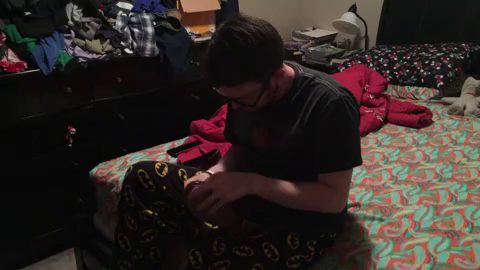

In [29]:
video_frames[0]

In [30]:
person_bbox['5GK8W.mp4/000044.png']
vidframe_id = '5GK8W.mp4/000044.png'
bboxes = []
try:
    keyframes = person_bbox[vidframe_id]['keypoints'][0]
except:
    keyframes=None
try:
    bboxes.append(('person', list(person_bbox[vidframe_id]['bbox'][0])))
except:
    bboxes = []
vid_id= vidframe_id.split('/')[0].split('.')[0]
frame_id= int(vidframe_id.split('/')[-1].split('.')[0])
video_frames = get_video_frames(f"/data/dataset/charades/video/Charades_v1_480/{vid_id}.mp4")
print(f"num frames: {len(video_frames)}; selected frame id {frame_id}")
og_img = video_frames[frame_id]
for obj in objs_bbox[vidframe_id]:
    #print(obj)
    if(obj['bbox'] is not None):
        bboxes.append((obj['class'], list(obj['bbox'])))


NameError: name 'person_bbox' is not defined

In [21]:
pred['scores']#.shape

tensor([0.9501, 0.9188, 0.8122, 0.5744, 0.7126, 0.5744, 0.3604, 0.5165, 0.3264,
        0.9581, 0.9889, 0.6038, 0.7784, 0.4296, 0.4551, 0.4847, 0.3235, 0.3137,
        0.4847, 0.6746, 0.9899, 0.6690, 0.5015, 0.4711, 0.4590, 0.6892, 0.7909,
        0.3651, 0.3284, 0.3931, 0.9370, 0.7714, 0.7343, 0.6570, 0.3599, 0.9493,
        0.6341, 0.7714, 0.9907, 0.5699, 0.3483, 0.7859, 0.8857, 0.7780, 0.7181,
        0.3000, 0.8582, 0.3781, 0.5874, 0.5643, 0.3668, 0.3483, 0.3000, 0.5699,
        0.9555, 0.7137, 0.5813, 0.8785, 0.5019, 0.7550, 0.8207, 0.3895, 0.3467,
        0.3525, 0.4665, 0.9973, 0.6976, 0.6333, 0.6093, 0.5195, 0.8402, 0.4312,
        0.5195, 0.3335, 0.4312, 0.6707, 0.5349, 0.3205, 0.3191, 0.9763, 0.3880,
        0.9969, 0.4521, 0.6216, 0.3591, 0.4368, 0.8649, 0.4368, 0.5845, 0.4368,
        0.3864, 0.4486, 0.3864, 0.9369, 0.9859, 0.3352, 0.9993, 0.4480, 0.4944,
        0.6415, 0.4152, 0.3835, 0.9846, 0.7744, 0.4944, 0.9992, 0.5217, 0.6505,
        0.4403, 0.5667, 0.4403, 0.9926, 

In [17]:
pred.keys()

dict_keys(['boxes', 'scores', 'distribution', 'pred_labels', 'features', 'fmaps', 'im_info', 'pred_scores', 'pair_idx', 'im_idx', 'human_idx', 'union_feat', 'union_box', 'spatial_masks', 'attention_distribution', 'spatial_distribution', 'contacting_distribution'])

In [ ]:
obj_bboxes_gt['001YG.mp4']['frames']

#vid_id
    #frames
        #frame_png_key
            #objs_list #(each has:)
                #'class': 
                #'bbox': (x1,y1,w,h)
                #'attention_relationship': []
                #'spatial_relationship': [],
                #'contacting_relationship':[]
                #'metadata': {'tag'}
                #'visible': True/False
    """
    [{'class': 'table',
  'bbox': (222.10317460317458,
   143.829365079365,
   257.77777777777777,
   101.11111111111109),
  'attention_relationship': ['unsure'],
  'spatial_relationship': ['in_front_of'],
  'contacting_relationship': ['not_contacting'],
  'metadata': {'tag': '001YG.mp4/table/000089', 'set': 'train'},
  'visible': True},
 {'class': 'chair',
  'bbox': (56.34126984126985,
   179.16666666666663,
   192.77777777777777,
   90.56890211160798),
  'attention_relationship': ['not_looking_at'],
  'spatial_relationship': ['beneath', 'behind'],
  'contacting_relationship': ['sitting_on', 'leaning_on'],
  'metadata': {'tag': '001YG.mp4/chair/000089', 'set': 'train'},
  'visible': True}]a
    """
    #vid_info
        #resolution
        #num_total_frames
        #num_salient_frames
    #